<a href="https://colab.research.google.com/github/Chekwube-Uzoegwu/Guest_Experience_Analytics_Topic_Modelling_Sentiment_Analysis_Project/blob/main/notebooks/GUEST_EXPERIENCE_ANALYTICS_SENTIMENT_ANALYSIS_EXPERIMENTATION_PHASE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Montra Hospitality Intel: Guest Experience Analytics, Topic Modelling and Sentiment Intelligence System

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Connecting to the SQL Database

### Database Connection Test

This cell creates a SQLAlchemy engine for the Neon PostgreSQL database and runs `SELECT 1` to confirm the connection works.

1. `sslmode="require"` makes the connection encrypted and `connect_timeout=10` stops it hanging.
2. `pool_pre_ping=True` and `pool_recycle=300` replace connections that Neon has closed while idle. Without them I kept getting a PendingRollbackError after the database went to sleep.

In [ ]:
# Install SQLAlchemy for database connections, psycopg2 as the PostgreSQL driver, and pandas for tables
!pip install sqlalchemy psycopg2-binary pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 49.7 MB/s eta 0:00:00


In [ ]:
# Import pandas to hold query results as DataFrames
import pandas as pd

# Import create_engine to build the database engine and text to wrap raw SQL strings for execution
from sqlalchemy import create_engine, text

In [ ]:
from google.colab import userdata

# Read the Neon PostgreSQL connection string from Colab Secrets, so the database password is never written in the notebook
DATABASE_URL = userdata.get("DATABASE_URL")

In [ ]:
# Build the engine from the connection string, forcing SSL encryption and giving up after 10 seconds if the server does not answer
# The "postgresql+psycopg2://" prefix names the psycopg2 driver explicitly, because newer SQLAlchemy versions default to a different driver
# pool_pre_ping sends a tiny test query before each use and silently replaces the connection if it has died
# pool_recycle discards any pooled connection older than 300 seconds, matching Neon's roughly 5 minute idle sleep
engine = create_engine(
    DATABASE_URL.replace("postgresql://", "postgresql+psycopg2://", 1),
    poolclass=None,
    pool_pre_ping=True,
    pool_recycle=300,
    connect_args={
        "sslmode": "require",
        "connect_timeout": 10
    }
)

# Open a connection, run SELECT 1 as a lightweight check, and print the returned row to prove the database responded
try:
    with engine.connect() as connection:
        result = connection.execute(text("SELECT 1"))
        print("Database response:", result.fetchone())
        print("Successfully connected to Neon!")

# If anything fails during connection or the query, catch the exception and print its full description
except Exception as e:
    print("Connection failed:", repr(e))

Database response: (1,)
Successfully connected to Neon!


## Retrieving Database Tables

This lists the tables in the `public` schema using `information_schema.tables`, so only the project tables show and not PostgreSQL's system tables.

In [ ]:
# Write a SQL query that reads table names from PostgreSQL's catalogue, keeping only tables in the public schema
query = """
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'public';
"""

# Send the query through the engine and return the result as a pandas DataFrame
tables = pd.read_sql(query, engine)

# Display the DataFrame so the list of available tables is shown below the cell
tables

,table_name
0,bookings
1,guests
2,hotels
3,reviews


## Loading the Database Tables

Each of the four tables is read into its own DataFrame with `pd.read_sql()`.

### Loading the Hotels Database Table

In [ ]:
# Send a SELECT * query through the engine to pull every row and column of the hotels table into a DataFrame
hotels_detail = pd.read_sql(
    "SELECT * FROM hotels",
    engine
)

# Display the first five rows to confirm the table loaded and to preview its columns
hotels_detail.head()

,hotel_id,hotel_name,location,star_rating,total_rooms
0,1,The Birmingham Grand,Birmingham,4,254
1,2,The London Heritage,London,5,234
2,3,The Oxford Boutique,Oxford,3,146
3,4,The Glasgow Heritage,Glasgow,3,84
4,5,Glasgow Metropolitan,Glasgow,4,214


### Loading the Guests Database Table

In [ ]:
# Send a SELECT * query through the engine to pull every row and column of the guests table into a DataFrame
guest_data = pd.read_sql(
    "SELECT * FROM guests",
    engine
)

# Display the first five rows to confirm the table loaded and to preview its columns
guest_data.head()

,guest_id,customer_type,loyalty_status,country,previous_stays
0,1,Leisure,None,Australia,0
1,2,Leisure,None,Germany,1
2,3,Business,Gold,United Kingdom,0
3,4,Family,Silver,United Arab Emirates,8
4,5,Corporate,None,France,0


### Loading the Customer Reviews Database Table

In [ ]:
# Send a SELECT * query through the engine to pull every row and column of the reviews table into a DataFrame
customer_review = pd.read_sql(
    "SELECT * FROM reviews",
    engine
)

# Display the first five rows to confirm the table loaded and to preview its columns
customer_review.head()

,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clea...",1.9,2025-03-13,negative
3,4,4,982,12,We were disappointed that the neighborhood was...,2.2,2026-03-18,negative
4,5,5,615,5,The room service was standard hotel fare for w...,3.3,2025-03-03,neutral


### Loading the Bookings Database Table

In [ ]:
# Send a SELECT * query through the engine to pull every row and column of the bookings table into a DataFrame
bookings_data = pd.read_sql(
    "SELECT * FROM bookings",
    engine
)

# Display the first five rows to confirm the table loaded and to preview its columns
bookings_data.head()

,booking_id,guest_id,hotel_id,room_type,booking_channel,check_in_date,check_out_date,total_amount,stay_duration
0,1,6699,18,Suite,Direct Website,2025-05-25,2025-05-26,296.44,1
1,2,11380,23,Deluxe,Corporate Portal,2025-01-09,2025-01-13,483.56,4
2,3,4812,13,Executive,Travel Agent,2025-03-04,2025-03-06,415.59,2
3,4,982,12,Family Room,Airbnb,2026-03-06,2026-03-09,601.18,3
4,5,615,5,Deluxe,Expedia,2025-02-25,2025-03-02,603.85,5


## Dataset Overview

`.info()` shows the rows, columns and data types of each table, and `.isna().sum()` counts the missing values.

In [ ]:
# Print the row count, column names, non null counts and data types of the bookings table
bookings_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   booking_id       35000 non-null  int64  
 1   guest_id         35000 non-null  int64  
 2   hotel_id         35000 non-null  int64  
 3   room_type        35000 non-null  object 
 4   booking_channel  35000 non-null  object 
 5   check_in_date    35000 non-null  object 
 6   check_out_date   35000 non-null  object 
 7   total_amount     35000 non-null  float64
 8   stay_duration    35000 non-null  int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 2.4+ MB


In [ ]:
# Flag every missing cell as True, then add up the True values column by column to count missing entries
bookings_data.isna().sum()

,0
booking_id,0
guest_id,0
hotel_id,0
room_type,0
booking_channel,0
check_in_date,0
check_out_date,0
total_amount,0
stay_duration,0


In [ ]:
# Print the row count, column names, non null counts and data types of the guests table
guest_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   guest_id        12000 non-null  int64 
 1   customer_type   12000 non-null  object
 2   loyalty_status  5964 non-null   object
 3   country         12000 non-null  object
 4   previous_stays  12000 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 468.9+ KB


In [ ]:
# Flag every missing cell as True, then add up the True values column by column to count missing entries
guest_data.isna().sum()

,0
guest_id,0
customer_type,0
loyalty_status,6036
country,0
previous_stays,0


In [ ]:
# Print the row count, column names, non null counts and data types of the hotels table
hotels_detail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   hotel_id     25 non-null     int64 
 1   hotel_name   25 non-null     object
 2   location     25 non-null     object
 3   star_rating  25 non-null     int64 
 4   total_rooms  25 non-null     int64 
dtypes: int64(3), object(2)
memory usage: 1.1+ KB


In [ ]:
# Flag every missing cell as True, then add up the True values column by column to count missing entries
hotels_detail.isna().sum()

,0
hotel_id,0
hotel_name,0
location,0
star_rating,0
total_rooms,0


In [ ]:
# Print the row count, column names, non null counts and data types of the reviews table
customer_review.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   review_id        35000 non-null  int64  
 1   booking_id       35000 non-null  int64  
 2   guest_id         35000 non-null  int64  
 3   hotel_id         35000 non-null  int64  
 4   review_text      35000 non-null  object 
 5   rating_score     35000 non-null  float64
 6   review_date      35000 non-null  object 
 7   sentiment_label  35000 non-null  object 
dtypes: float64(1), int64(4), object(3)
memory usage: 2.1+ MB


In [ ]:
# Flag every missing cell as True, then add up the True values column by column to count missing entries
customer_review.isna().sum()

,0
review_id,0
booking_id,0
guest_id,0
hotel_id,0
review_text,0
rating_score,0
review_date,0
sentiment_label,0


### Observations

1. **Bookings:** 35,000 rows, 9 columns, no missing values. The check in and check out dates are stored as text.
2. **Guests:** 12,000 rows, 5 columns. `loyalty_status` has 6,036 missing values (about half). These are guests outside the loyalty programme, so they will be filled with "Non-member" instead of being dropped.
3. **Hotels:** 25 rows, 5 columns, no missing values.
4. **Reviews:** 35,000 rows, 8 columns, no missing values. `review_text` is the input and `sentiment_label` is the target. `rating_score` is excluded from the features because the label comes from it.
5. Bookings and reviews both have 35,000 rows, so each booking links to exactly one review through `booking_id`.

## Data Validation, Cleaning and Formatting

### Formatting Date Columns from Objects to Proper Date Format

The date columns were loaded as text, so they are converted to datetime.

In [ ]:
# Import numpy, which provides the floor function used for standard rounding later
import numpy as np

# Parse each text date such as "2025-05-25" into a pandas datetime value so dates can be compared and subtracted
bookings_data['check_in_date'] = pd.to_datetime(bookings_data['check_in_date'])
bookings_data['check_out_date'] = pd.to_datetime(bookings_data['check_out_date'])
customer_review['review_date'] = pd.to_datetime(customer_review['review_date'])

# Print the data type of each converted column to confirm it now reads datetime64 instead of object
print(bookings_data[['check_in_date', 'check_out_date']].dtypes)
print(customer_review[['review_date']].dtypes)

check_in_date     datetime64[ns]
check_out_date    datetime64[ns]
dtype: object
review_date    datetime64[ns]
dtype: object


### Rounding rating_score to the Nearest Whole Number

A rounded copy is stored in `rating_rounded` so the original decimals are kept. I used `np.floor(rating + 0.5)` instead of `.round()` because pandas rounds half to even, which would have pushed 1,242 reviews rated 2.5 and 496 rated 4.5 down a whole point. This column is only for interpretation, not a model feature.

In [ ]:
# Add 0.5 to each rating then take the floor, so any value ending in .5 always rounds up, then store as whole number integers in a new column
customer_review['rating_rounded'] = np.floor(customer_review['rating_score'] + 0.5).astype(int)

# Count how many reviews fall into each whole number rating from 1 to 5, sorted by rating
customer_review['rating_rounded'].value_counts().sort_index()

,count
rating_rounded,
1,1719
2,7943
3,13766
4,9065
5,2507


### Data Validation: Identifying Rows Where Check In Is Later Than Check Out

In [ ]:
# Keep only the bookings whose check in date falls after their check out date, which would be logically impossible
invalid_dates = bookings_data[bookings_data['check_in_date'] > bookings_data['check_out_date']]

# If any such rows exist, report how many and display them, otherwise confirm the check passed
if not invalid_dates.empty:
    print(f"Found {len(invalid_dates)} rows with invalid dates:")
    display(invalid_dates)
else:
    print("Data Validation Passed: No rows found where check-in date is greater than check-out date.")

Data Validation Passed: No rows found where check-in date is greater than check-out date.


### Data Validation: Stay Duration and Review Timing

Two checks: `stay_duration` should equal the nights between check in and check out, and no review should be written before check out.

In [ ]:
# Subtract check in from check out to get a time gap, convert it to whole days, and flag bookings where it differs from the recorded stay_duration
duration_mismatch = bookings_data[
    (bookings_data['check_out_date'] - bookings_data['check_in_date']).dt.days != bookings_data['stay_duration']
]
print(f"Bookings where stay_duration does not match the dates: {len(duration_mismatch)}")

# Join each review to its booking using booking_id so the review date and check out date sit on the same row
review_timing = customer_review.merge(
    bookings_data[['booking_id', 'check_out_date']],
    on='booking_id',
    how='left'
)

# Flag reviews dated earlier than the guest's check out, then report the count
early_reviews = review_timing[review_timing['review_date'] < review_timing['check_out_date']]
print(f"Reviews written before check-out: {len(early_reviews)}")

# Measure the number of days between check out and review for every row and summarise the spread
print("\nDays between check-out and review:")
print((review_timing['review_date'] - review_timing['check_out_date']).dt.days.describe())

Bookings where stay_duration does not match the dates: 0
Reviews written before check-out: 0

Days between check-out and review:
count    35000.000000
mean         7.008286
std          4.327844
min          0.000000
25%          3.000000
50%          7.000000
75%         11.000000
max         14.000000
dtype: float64


### Filling Missing Values

**Task: filling the loyalty status with a tangible name and why that name is used**

The 6,036 missing values in `loyalty_status` are not lost information. They are guests who are not enrolled in the loyalty programme, since the other values (Silver, Gold, Platinum) are membership tiers. Dropping them would remove half of all guests, so they are filled with a category that describes them instead.

The name **"Non-member"** is used for three reasons:

1. It accurately describes the guest's relationship with the loyalty programme, so it makes sense in any grouping or chart.
2. It avoids the text value "None", which pandas converts back into a missing value when a CSV file is saved and reloaded, silently undoing the fill.
3. It cannot be confused with Python's built in `None` object.

In [ ]:
# Replace every missing value in loyalty_status with the text "Non-member", leaving existing tiers unchanged
guest_data['loyalty_status'] = guest_data['loyalty_status'].fillna("Non-member")

# Count remaining missing values in the column to confirm the fill worked, which should print 0
print("Null counts in loyalty_status:", guest_data['loyalty_status'].isna().sum())

# Count guests in each loyalty category, including the new Non-member group
print(guest_data['loyalty_status'].value_counts())

# Display the first five rows to show the filled values in context
display(guest_data.head())

Null counts in loyalty_status: 0
loyalty_status
Non-member    6036
Silver        2951
Gold          1998
Platinum      1015
Name: count, dtype: int64


,guest_id,customer_type,loyalty_status,country,previous_stays
0,1,Leisure,Non-member,Australia,0
1,2,Leisure,Non-member,Germany,1
2,3,Business,Gold,United Kingdom,0
3,4,Family,Silver,United Arab Emirates,8
4,5,Corporate,Non-member,France,0


## Exploratory Data Analysis

EDA is mainly the Data Analyst's part, so I kept it short. It gives business context for the NLP work that follows.

### Booking Data Analysis Overview

Bookings and revenue by room type and by booking channel.

In [ ]:
# Import plotly graph objects to build individual bar traces and make_subplots to arrange them in a grid
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Count bookings per room type, turn the result into a two column table and sort from most to fewest
room_type_counts = bookings_data['room_type'].value_counts().reset_index()
room_type_counts.columns = ['room_type', 'count']

# 2. Add up total_amount within each room type to get revenue, then sort from highest to lowest
room_revenue = (bookings_data.groupby('room_type')['total_amount']
                .sum().reset_index()
                .sort_values('total_amount', ascending=False))

# 3. Count bookings per booking channel, turn the result into a two column table and sort from most to fewest
channel_counts = bookings_data['booking_channel'].value_counts().reset_index()
channel_counts.columns = ['booking_channel', 'count']

# 4. Add up total_amount within each booking channel to get revenue, then sort from highest to lowest
channel_revenue = (bookings_data.groupby('booking_channel')['total_amount']
                   .sum().reset_index()
                   .sort_values('total_amount', ascending=False))

# Fix one colour for booking counts and one for revenue so each colour means the same measure in every panel
COUNT_COLOUR = '#2a7f8f'
REVENUE_COLOUR = '#b5543c'

# Create a 2 by 2 grid of bar chart panels, each with its own title
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=("Total Bookings by Room Type", "Total Revenue by Room Type",
                    "Total Bookings by Booking Channel", "Total Revenue by Booking Channel"),
    vertical_spacing=0.18
)

# Place a bar trace in each grid position, printing the value above each bar, with revenue formatted as pounds in millions
fig.add_trace(go.Bar(x=room_type_counts['room_type'], y=room_type_counts['count'],
                     marker_color=COUNT_COLOUR, text=room_type_counts['count'],
                     texttemplate='%{text:,}', textposition='outside', name='Bookings'), row=1, col=1)
fig.add_trace(go.Bar(x=room_revenue['room_type'], y=room_revenue['total_amount'],
                     marker_color=REVENUE_COLOUR, text=room_revenue['total_amount'] / 1e6,
                     texttemplate='£%{text:.2f}M', textposition='outside', name='Revenue'), row=1, col=2)
fig.add_trace(go.Bar(x=channel_counts['booking_channel'], y=channel_counts['count'],
                     marker_color=COUNT_COLOUR, text=channel_counts['count'],
                     texttemplate='%{text:,}', textposition='outside', name='Bookings'), row=2, col=1)
fig.add_trace(go.Bar(x=channel_revenue['booking_channel'], y=channel_revenue['total_amount'],
                     marker_color=REVENUE_COLOUR, text=channel_revenue['total_amount'] / 1e6,
                     texttemplate='£%{text:.2f}M', textposition='outside', name='Revenue'), row=2, col=2)

# Prefix revenue axis ticks with a pound sign so the scale reads as currency
fig.update_yaxes(tickprefix='£', row=1, col=2)
fig.update_yaxes(tickprefix='£', row=2, col=2)

# Set the overall figure height, main title and a clean white background, hiding the legend because panel titles already name each measure
fig.update_layout(height=800, title_text="Booking Data Analysis Overview",
                  showlegend=False, template='plotly_white')
fig.show()

In [ ]:
# Build a summary table per room type holding booking count, total revenue and average booking value
room_summary = bookings_data.groupby('room_type').agg(
    bookings=('booking_id', 'size'),
    revenue=('total_amount', 'sum'),
    avg_booking_value=('total_amount', 'mean')
)

# Convert bookings and revenue into percentage shares of their column totals so volume and value can be compared directly
room_summary['booking_share_%'] = (room_summary['bookings'] / room_summary['bookings'].sum() * 100).round(1)
room_summary['revenue_share_%'] = (room_summary['revenue'] / room_summary['revenue'].sum() * 100).round(1)

# Sort by revenue from highest to lowest and round money columns to two decimal places for display
room_summary.sort_values('revenue', ascending=False).round(2)

,bookings,revenue,avg_booking_value,booking_share_%,revenue_share_%
room_type,,,,,
Deluxe,8619,3938732.66,456.98,24.6,24.1
Executive,5293,3211430.94,606.73,15.1,19.7
Standard,10596,3112788.77,293.77,30.3,19.1
Suite,3544,3029593.14,854.85,10.1,18.6
Family Room,4137,2158312.62,521.71,11.8,13.2
Twin,2811,861141.58,306.35,8.0,5.3


### Observations

1. **Standard rooms drive volume but not value:** 30.3% of bookings but only 19.1% of revenue (average booking about £294).
2. **Deluxe rooms are the largest revenue source** at about £3.94M (24.1%).
3. **Suites and Executive rooms earn above their share.** Together they bring 38.3% of revenue from 25.2% of bookings. Suites have the highest average booking at about £855.
4. **Channels differ in volume, not value.** Direct Website (24.8%) and Booking.com (22.3%) bring almost half the bookings, but the average booking is £460 to £470 on every channel.
5. Total revenue is about £16.31M.

### Guest Stay Duration Distribution

I used a bar per number of nights instead of a histogram because `stay_duration` only takes whole values, and histogram bins would hide gaps.

In [ ]:
# Import plotly express for quick single figure charts
import plotly.express as px

# Count bookings for each number of nights, then reindex over every value from the minimum to the maximum so any missing duration appears as a zero bar rather than disappearing
stay_counts = (bookings_data['stay_duration']
               .value_counts()
               .reindex(range(bookings_data['stay_duration'].min(), bookings_data['stay_duration'].max() + 1), fill_value=0)
               .rename_axis('stay_duration')
               .reset_index(name='bookings'))

# Divide each count by the total number of bookings and multiply by 100 to get its percentage share
stay_counts['share_%'] = (stay_counts['bookings'] / stay_counts['bookings'].sum() * 100).round(1)

# Draw one bar per number of nights, labelling each bar with its percentage share
fig_stay = px.bar(stay_counts, x='stay_duration', y='bookings', text='share_%',
                  title='Distribution of Guest Stay Duration (Nights)',
                  labels={'stay_duration': 'Nights Stayed', 'bookings': 'Number of Bookings'},
                  color_discrete_sequence=['#2a7f8f'], template='plotly_white')

# Show every whole number on the x axis and append a percent sign to each bar label
fig_stay.update_xaxes(dtick=1)
fig_stay.update_traces(texttemplate='%{text}%', textposition='outside')
fig_stay.show()

# Print the mean and median stay alongside the underlying table
print(f"Mean stay: {bookings_data['stay_duration'].mean():.2f} nights | Median stay: {bookings_data['stay_duration'].median():.0f} nights")
stay_counts

Mean stay: 2.95 nights | Median stay: 3 nights


,stay_duration,bookings,share_%
0,1,5299,15.1
1,2,10425,29.8
2,3,8679,24.8
3,4,5243,15.0
4,5,3614,10.3
5,6,0,0.0
6,7,1740,5.0


### Observations

1. **Short stays dominate.** Two nights is the most common (29.8%), and one to three nights make up 69.7% of bookings. Mean 2.95, median 3.
2. **There are no six night stays, yet 1,740 bookings (5.0%) are exactly seven nights.** This points to a weekly package or rate. Worth confirming with operations.
3. Average stay is almost the same for every room type (2.91 to 2.99 nights).

### Revenue by Booking Channel and Room Type

A heatmap instead of a grouped bar chart, since 7 channels by 6 room types would be 42 bars. Each cell is the share of that channel's revenue from each room type, so channels of different sizes compare on the same scale.

In [ ]:
# Add up total_amount for every booking channel and room type pair, producing a grid with channels as rows and room types as columns
channel_room_revenue = bookings_data.pivot_table(index='booking_channel', columns='room_type',
                                                 values='total_amount', aggfunc='sum')

# Divide each cell by its row total and multiply by 100, so every row shows how that channel's revenue splits across room types
channel_room_share = channel_room_revenue.div(channel_room_revenue.sum(axis=1), axis=0).mul(100).round(1)

# Order rows from highest to lowest total channel revenue and columns from highest to lowest total room type revenue
row_order = channel_room_revenue.sum(axis=1).sort_values(ascending=False).index
col_order = channel_room_revenue.sum(axis=0).sort_values(ascending=False).index
channel_room_share = channel_room_share.loc[row_order, col_order]

# Draw the grid as a single hue heatmap, where darker cells mean a larger share, and print each percentage inside its cell
fig_combined = px.imshow(channel_room_share, text_auto='.1f', aspect='auto',
                         color_continuous_scale='Blues',
                         title='Share of Each Channel\'s Revenue by Room Type (%)',
                         labels={'x': 'Room Type', 'y': 'Booking Channel', 'color': 'Revenue share (%)'})
fig_combined.update_layout(template='plotly_white', height=500)
fig_combined.show()

# For each room type, subtract its lowest channel share from its highest to measure how much the mix varies between channels
print("Spread in revenue share across channels (percentage points):")
print((channel_room_share.max() - channel_room_share.min()).round(1))

# Flatten the revenue grid into a single list of channel and room type pairs, then show the three highest and three lowest earning pairs
combo_revenue = channel_room_revenue.stack().sort_values(ascending=False)
print("\nTop 3 channel and room type combinations by revenue (£):")
print(combo_revenue.head(3).round(0))
print("\nBottom 3 channel and room type combinations by revenue (£):")
print(combo_revenue.tail(3).round(0))

Spread in revenue share across channels (percentage points):
room_type
Deluxe         2.8
Executive      3.1
Standard       1.0
Suite          1.9
Family Room    1.2
Twin           0.5
dtype: float64

Top 3 channel and room type combinations by revenue (£):
booking_channel  room_type
Direct Website   Deluxe       977969.0
Booking.com      Deluxe       909166.0
Direct Website   Executive    805055.0
dtype: float64

Bottom 3 channel and room type combinations by revenue (£):
booking_channel  room_type
Travel Agent     Twin         86303.0
Airbnb           Twin         83619.0
Walk-in          Twin         71155.0
dtype: float64


### Observations

1. **Every channel sells the same room mix.** Deluxe always has the largest share (22.1% to 24.9%) and Twin the smallest. No room type share moves by more than 3.1 points between channels.
2. The top combinations (Direct Website with Deluxe, about £978K) just reflect the biggest channels meeting the highest earning rooms.
3. **Booking channel affects how many bookings come in, not what guests book or spend.**

### Guest Distribution by Country

All 15 countries are shown.

In [ ]:
# Count guests per country, turning the result into a two column table sorted from most to fewest guests
country_dist = guest_data['country'].value_counts().reset_index()
country_dist.columns = ['country', 'guest_count']

# Divide each country's count by the total number of guests and multiply by 100 to get its percentage share
country_dist['share_%'] = (country_dist['guest_count'] / country_dist['guest_count'].sum() * 100).round(1)

# Draw one bar per country in a single colour, labelling each bar with its percentage share
fig_country = px.bar(country_dist, x='country', y='guest_count', text='share_%',
                     title=f'Guest Distribution by Country (All {len(country_dist)} Countries)',
                     labels={'country': 'Country', 'guest_count': 'Number of Guests'},
                     color_discrete_sequence=['#2a7f8f'], template='plotly_white')

# Append a percent sign to each bar label and place it above the bar
fig_country.update_traces(texttemplate='%{text}%', textposition='outside')
fig_country.show()

# Add up the shares of the five largest countries to measure how concentrated the guest base is
print(f"Share of guests from the top 5 countries: {country_dist['share_%'].head(5).sum():.1f}%")

Share of guests from the top 5 countries: 70.1%


### Observations

1. **The UK is the main market** at 34.8% of guests (4,174), which is expected since all 25 hotels are in the UK.
2. The US (12.2%) and Nigeria (9.8%) are the largest international markets. The top five countries hold 70.1% of guests.
3. Australia and China (0.5% each) and India (1.0%) are too small for reliable country comparisons later.

### Distribution of Customer Types

In [ ]:
# Count guests per customer type, turning the result into a two column table sorted from most to fewest
cust_type_dist = guest_data['customer_type'].value_counts().reset_index()
cust_type_dist.columns = ['customer_type', 'count']

# Draw a donut chart where each slice's size is its guest count, with a 40% hole in the centre
fig_type = px.pie(cust_type_dist, names='customer_type', values='count',
                  title='Distribution of Customer Types', hole=0.4,
                  color_discrete_sequence=px.colors.qualitative.Safe)

# Print both the category name and its percentage on each slice
fig_type.update_traces(textinfo='label+percent')
fig_type.show()

### Observations

1. **Leisure is the largest segment** at 39.9%.
2. Business (24.4%) and Corporate (15.6%) together make 40.0%, the same size as Leisure.
3. Group and Family are 10.0% each. No segment is above 40%.

### Customer Type by Country

Only the 10 largest countries are used, because the small ones give unreliable percentages. A chi-square test checks whether the differences between countries are real or just chance.

In [ ]:
# Import the chi-square test of independence, which checks whether two categorical variables are related
from scipy.stats import chi2_contingency

# Keep only guests from the 10 countries with the most guests
top_countries = guest_data['country'].value_counts().head(10).index
top_country_guests = guest_data[guest_data['country'].isin(top_countries)]

# Cross tabulate country against customer type, dividing each row by its total so every country's row sums to 100%
country_type_pct = pd.crosstab(top_country_guests['country'], top_country_guests['customer_type'],
                               normalize='index').mul(100).round(1)

# Reorder rows from largest to smallest country so the heatmap reads in order of market size
country_type_pct = country_type_pct.loc[top_countries]

# Draw the table as a single hue heatmap, where darker cells mean a larger share, and print each percentage inside its cell
fig_ct = px.imshow(country_type_pct, text_auto='.1f', aspect='auto', color_continuous_scale='Blues',
                   title='Customer Type Mix within the Top 10 Countries (%)',
                   labels={'x': 'Customer Type', 'y': 'Country', 'color': 'Share of guests (%)'})
fig_ct.update_layout(template='plotly_white', height=500)
fig_ct.show()

# Run the chi-square test on raw guest counts, which compares observed counts with the counts expected if country and customer type were unrelated
chi2, p_value, dof, expected = chi2_contingency(
    pd.crosstab(top_country_guests['country'], top_country_guests['customer_type'])
)
print(f"Chi-square statistic: {chi2:.1f} | Degrees of freedom: {dof} | p-value: {p_value:.4f}")

# A p-value below 0.05 would suggest a real relationship between country and customer type
if p_value < 0.05:
    print("Result: Customer type mix differs significantly between countries.")
else:
    print("Result: No significant relationship. Differences between countries are consistent with random variation.")

Chi-square statistic: 45.3 | Degrees of freedom: 36 | p-value: 0.1382
Result: No significant relationship. Differences between countries are consistent with random variation.


### Observations

1. **Every major market has the same customer mix.** Leisure leads in all 10 countries (36.7% to 44.0%), then Business.
2. **The differences are not significant** (chi-square p-value about 0.14, above 0.05).
3. So segment based marketing can be applied the same way across countries.

### Room Type Bookings and Capacity per Hotel

Hotels are labelled by name and `hotel_id` because two different hotels are both called "Edinburgh Riverside Hotel" (id 9 with 71 rooms and id 14 with 215 rooms). Grouping by name alone would merge them into one fake hotel with 286 rooms.

In [ ]:
# Build a unique label for each hotel by joining its name and ID, so the two hotels sharing a name stay separate on every chart
hotels_detail['hotel_label'] = hotels_detail['hotel_name'] + " (" + hotels_detail['hotel_id'].astype(str) + ")"

# Merge bookings with hotel details by matching hotel_id, attaching each booking's hotel label and room capacity
hotel_room_analysis = pd.merge(bookings_data, hotels_detail[['hotel_id', 'hotel_label', 'total_rooms']], on='hotel_id')

# Group by hotel and room type and count the rows in each group, storing the count in a new column named booked_count
room_type_by_hotel = hotel_room_analysis.groupby(['hotel_label', 'total_rooms', 'room_type']).size().reset_index(name='booked_count')

# Draw one bar per hotel, stacking a coloured segment for each room type's booking count
fig_room_dist = px.bar(room_type_by_hotel, x='hotel_label', y='booked_count', color='room_type',
                       title='Room Type Distribution per Hotel (Relative to Bookings)',
                       labels={'booked_count': 'Number of Bookings', 'hotel_label': 'Hotel'},
                       barmode='stack')

# Tilt the hotel names by 45 degrees so they do not overlap
fig_room_dist.update_layout(xaxis_tickangle=-45)
fig_room_dist.show()

# Draw one bar per hotel showing its total room capacity, shaded by the same capacity value
fig_capacity = px.bar(hotels_detail, x='hotel_label', y='total_rooms',
                      title='Total Room Capacity per Hotel',
                      labels={'hotel_label': 'Hotel', 'total_rooms': 'Total Rooms'},
                      color='total_rooms')

# Tilt the hotel names by 45 degrees so they do not overlap
fig_capacity.update_layout(xaxis_tickangle=-45)
fig_capacity.show()

### Observations

1. **Every hotel sells the same room mix**, led by Standard and Deluxe.
2. **Capacity ranges from 71 rooms** (Edinburgh Riverside Hotel, 9) **to 265** (London Metropolitan, 19).
3. **Booking volume does not depend on size.** Every hotel gets roughly 1,300 to 1,500 bookings.
4. So smaller hotels handle far more bookings per room, which could put pressure on housekeeping and room readiness. I come back to this in the sentiment analysis.

### Revenue Analysis by Hotel and Room Type

Revenue rate is `total_amount / stay_duration` (revenue per night). Hotels are grouped by `hotel_label` so the two Edinburgh Riverside hotels stay separate.

In [ ]:
# Divide each booking's total amount by its number of nights to get the revenue earned per night
bookings_data['revenue_rate'] = bookings_data['total_amount'] / bookings_data['stay_duration']

# Merge bookings with hotel details by matching hotel_id, attaching each booking's unique hotel label and room capacity
hotel_room_analysis = pd.merge(
    bookings_data,
    hotels_detail[['hotel_id', 'hotel_label', 'total_rooms']],
    on='hotel_id'
)

# For each hotel, add up total revenue, average the nightly rate and count its bookings
revenue_per_hotel = hotel_room_analysis.groupby('hotel_label').agg(
    total_revenue=('total_amount', 'sum'),
    avg_revenue_rate=('revenue_rate', 'mean'),
    total_bookings=('booking_id', 'count')
).reset_index()

# For each hotel and room type pair, add up revenue, average the nightly rate and count bookings
revenue_by_room_type = hotel_room_analysis.groupby(
    ['hotel_label', 'room_type']
).agg(
    total_revenue=('total_amount', 'sum'),
    avg_rate=('revenue_rate', 'mean'),
    bookings=('booking_id', 'count')
).reset_index()

# Draw one bar per hotel for total revenue, shading each bar by its average nightly rate and printing the value in short form such as 650k
fig_rev_hotel = px.bar(
    revenue_per_hotel, x='hotel_label', y='total_revenue',
    title='Total Revenue per Hotel',
    labels={'total_revenue': 'Revenue', 'hotel_label': 'Hotel', 'avg_revenue_rate': 'Avg Nightly Rate'},
    color='avg_revenue_rate', color_continuous_scale='Viridis', text_auto='.2s'
)
fig_rev_hotel.update_layout(xaxis_tickangle=-45)
fig_rev_hotel.show()

# Draw one bar per hotel, stacking a coloured segment for each room type's revenue and printing each segment's value in short form
fig_rev_room = px.bar(
    revenue_by_room_type, x='hotel_label', y='total_revenue',
    color='room_type', barmode='stack',
    title='Revenue by Room Type per Hotel',
    labels={'total_revenue': 'Revenue', 'hotel_label': 'Hotel'}, text_auto='.2s'
)
fig_rev_room.update_layout(xaxis_tickangle=-45)
fig_rev_room.show()

### Observations

1. **Revenue is spread fairly evenly**, from about £595K (Liverpool Metropolitan, 21) to £709K (Southampton Park Hotel, 10).
2. **The top earners are among the smallest hotels** (Southampton Park, 80 rooms, and Edinburgh Riverside 9, 71 rooms).
3. **5 star hotels do not earn more.** Liverpool Metropolitan and London Metropolitan, both 5 star, earn the least.
4. **Nightly rates are almost the same across hotels** (£154 to £160). The colour scale exaggerates this £6 range. Rate is driven by room type, from about £99 (Standard) to £286 (Suite).
5. Every hotel has the same room type revenue mix, led by Deluxe at about 24%.

### Revenue by Booking Channel per Hotel

Grouped by `hotel_label` so the two Edinburgh Riverside hotels are shown separately.

In [ ]:
# For each hotel and booking channel pair, add up total_amount to get the revenue that channel brought to that hotel
revenue_by_channel = hotel_room_analysis.groupby(
    ['hotel_label', 'booking_channel']
).agg(
    total_revenue=('total_amount', 'sum')
).reset_index()

# Draw one bar per hotel, stacking a coloured segment for each channel's revenue and printing each value in short form such as 150k
fig_rev_channel = px.bar(
    revenue_by_channel, x='hotel_label', y='total_revenue',
    color='booking_channel', barmode='stack',
    title='Revenue by Booking Channel per Hotel',
    labels={'total_revenue': 'Revenue', 'hotel_label': 'Hotel', 'booking_channel': 'Booking Channel'}, text_auto='.2s'
)

# Tilt hotel names by 45 degrees, force a label under every bar and make the chart taller so all names fit
fig_rev_channel.update_layout(xaxis_tickangle=-45, height=600)
fig_rev_channel.update_xaxes(tickmode='linear')
fig_rev_channel.show()

### Observations

1. **Direct Website leads at 22 of 25 hotels**, about 25% of revenue on average. Booking.com is close behind at about 22%.
2. **OTAs together are the biggest source.** Booking.com and Expedia make about 37% of a typical hotel's revenue. OTA bookings carry commission, so the strong direct share is valuable.
3. Every hotel has a similar channel mix (no channel varies by more than about 6 points).

### Rating Score and Sentiment Label Distribution

The rating chart uses `rating_rounded`, the half up rounded rating from earlier.

In [ ]:
# 1. Rating score distribution
# Count reviews at each whole number rating and draw them as bars, using 5 bins for the 5 possible ratings
fig_rating = px.histogram(customer_review, x='rating_rounded',
                          title='Distribution of Rating Scores',
                          nbins=5,
                          labels={'rating_rounded': 'Rating (rounded)'},
                          color_discrete_sequence=['#636EFA'])

# Leave a small gap between bars so each rating reads as a separate category
fig_rating.update_layout(bargap=0.1, yaxis_title='Number of Reviews')

# Put a tick label under every whole number rating from 1 to 5
fig_rating.update_xaxes(dtick=1)
fig_rating.show()

# 2. Sentiment label distribution
# Count reviews per sentiment label, turning the result into a two column table
sentiment_dist = customer_review['sentiment_label'].value_counts().reset_index()
sentiment_dist.columns = ['sentiment_label', 'count']

# Draw a pie chart where each slice's size is its review count, fixing green for positive, grey for neutral and red for negative
fig_sentiment = px.pie(sentiment_dist, names='sentiment_label', values='count',
                       title='Sentiment Label Distribution',
                       color='sentiment_label',
                       color_discrete_map={'positive': 'green', 'neutral': 'gray', 'negative': 'red'})

# Print both the label and its percentage on each slice
fig_sentiment.update_traces(textinfo='label+percent')
fig_sentiment.show()

### Observations

1. **Ratings cluster in the middle.** 3 is most common (about 13,800 reviews), and 1 and 5 are least common.
2. **Neutral is the largest class** (38.2%), then positive (33.7%) and negative (28.2%).
3. **The classes are balanced enough** that resampling is not needed, but I still use macro F1 so every class counts equally.
4. Rating and sentiment follow the same pattern because the label comes from the rating, which confirms the rating must stay out of the features.

### Sentiment Distribution per Hotel

The aim is to see which hotels are likely to be recommended (more positive than negative reviews). Reviews are merged with hotel details into a new DataFrame, `review_hotel`, so `customer_review` stays unchanged.

In [ ]:
# Attach each review's hotel label and star rating by matching hotel_id, storing the result in a new DataFrame so customer_review stays unchanged
review_hotel = pd.merge(customer_review, hotels_detail[['hotel_id', 'hotel_label', 'star_rating']], on='hotel_id')

# Count reviews for every hotel and sentiment label pair, storing the count in a new column named count
sentiment_by_hotel = review_hotel.groupby(
    ['hotel_label', 'sentiment_label']
).size().reset_index(name='count')

# Draw grouped bars so each hotel shows its positive, neutral and negative counts side by side, in fixed green, grey and red
fig_sentiment_hotel = px.bar(sentiment_by_hotel, x='hotel_label', y='count',
                             color='sentiment_label', barmode='group',
                             title='Sentiment Distribution per Hotel',
                             labels={'count': 'Number of Reviews', 'hotel_label': 'Hotel', 'sentiment_label': 'Sentiment'},
                             color_discrete_map={'positive': 'green', 'neutral': 'gray', 'negative': 'red'})

# Tilt hotel names by 45 degrees, force a label under every hotel and make the chart taller so all names fit
fig_sentiment_hotel.update_layout(xaxis_tickangle=-45, height=600)
fig_sentiment_hotel.update_xaxes(tickmode='linear')
fig_sentiment_hotel.show()

### Observations

1. **Star rating separates the hotels.** Every 4 and 5 star hotel has more positive than negative reviews, and every 3 star hotel has more negative than positive.
2. **Nottingham Riverside Hotel (11)** is the most likely to be recommended (about 709 positive against 248 negative).
3. **The two Edinburgh Riverside hotels (9 and 14)** are the least likely, each with over 500 negative and under 400 positive. Glasgow Skyline Hotel (16) is similar.
4. Neutral is the largest group at most hotels.
5. Topic modelling will show which aspects drive the negative sentiment at 3 star hotels.

### Temporal Trend Analysis

Monthly review volume, check ins and check outs.

In [ ]:
# Temporal Trend Analysis: Reviews over time
# Convert each review date to its calendar month, count the reviews in each month and store the count in a column named review_count
review_trend = customer_review.groupby(customer_review['review_date'].dt.to_period('M')).size().reset_index(name='review_count')

# Turn each monthly period back into a timestamp (the first day of the month) so plotly can place it on a date axis
review_trend['review_date'] = review_trend['review_date'].dt.to_timestamp()

# Draw a line joining the monthly review counts in date order
fig_review_trend = px.line(review_trend, x='review_date', y='review_count',
                           title='Monthly Review Trend',
                           labels={'review_count': 'Number of Reviews', 'review_date': 'Month'})
fig_review_trend.show()

# Check-in vs Check-out Trend Analysis
# Count bookings by the month of check in, and separately by the month of check out
checkin_trend = bookings_data.groupby(bookings_data['check_in_date'].dt.to_period('M')).size().reset_index(name='check_in_count')
checkout_trend = bookings_data.groupby(bookings_data['check_out_date'].dt.to_period('M')).size().reset_index(name='check_out_count')

# Convert both monthly periods into timestamps stored in a shared column named date, so the two tables can be joined
checkin_trend['date'] = checkin_trend['check_in_date'].dt.to_timestamp()
checkout_trend['date'] = checkout_trend['check_out_date'].dt.to_timestamp()

# Join the two monthly tables on date, keeping every month that appears in either table
combined_trend = pd.merge(checkin_trend[['date', 'check_in_count']],
                          checkout_trend[['date', 'check_out_count']], on='date', how='outer')

# Draw two lines on the same axes, one for monthly check ins and one for monthly check outs
fig_booking_trend = px.line(combined_trend, x='date', y=['check_in_count', 'check_out_count'],
                            title='Monthly Check-in vs Check-out Trends',
                            labels={'value': 'Count', 'date': 'Month', 'variable': 'Event'})
fig_booking_trend.show()

### Observations

1. **Activity is stable.** From February 2025 to May 2026, monthly reviews stay between about 1,850 and 2,100 and check ins between about 1,860 and 2,080. No seasonal peak.
2. February dips in both years, which fits it being the shortest month.
3. **The first and last months are incomplete.** January 2025 has fewer reviews because reviews come up to 14 days after check out. June 2026 drops because the data ends partway through the month.
4. Since volume is stable, any change in sentiment over time cannot be explained by how many guests are reviewing.

### Average Guest Rating by Hotel

The average uses the original decimal `rating_score`, plotted by `hotel_label`. Grouping by name would stack the two Edinburgh Riverside averages into one bar of about 5.7, which is impossible on a 1 to 5 scale.

In [ ]:
# Average Rating Score by Hotel
# Group reviews by hotel_id and take the mean of rating_score within each hotel
hotel_ratings = customer_review.groupby('hotel_id')['rating_score'].mean().reset_index()

# Attach each hotel's unique label by matching on hotel_id
hotel_ratings = pd.merge(hotel_ratings, hotels_detail[['hotel_id', 'hotel_label']], on='hotel_id')

# Sort hotels from highest to lowest average rating, then draw one bar per hotel shaded from red (low) to green (high)
fig_hotel_avg_rating = px.bar(hotel_ratings.sort_values('rating_score', ascending=False),
                              x='hotel_label', y='rating_score',
                              title='Average Guest Rating by Hotel',
                              labels={'rating_score': 'Avg Rating', 'hotel_label': 'Hotel'},
                              color='rating_score', color_continuous_scale='RdYlGn')

# Tilt hotel names by 45 degrees, force a label under every bar and make the chart taller so all names fit
fig_hotel_avg_rating.update_layout(xaxis_tickangle=-45, height=600)
fig_hotel_avg_rating.update_xaxes(tickmode='linear')
fig_hotel_avg_rating.show()

### Observations

1. **Ratings fall into three bands that match star ratings with no overlap:** 5 star about 3.30 to 3.39, 4 star about 3.08 to 3.12, 3 star about 2.83 to 2.90.
2. Nottingham Riverside Hotel (11) is highest at about 3.39. Glasgow Skyline (16) and Edinburgh Riverside (14) are lowest at about 2.83.
3. **Even the best hotels average only about 3.4 out of 5**, so satisfaction is moderate across the portfolio.
4. This matches the sentiment per hotel chart.

## Merging Datasets

The four tables are joined into one dataset. Each review links to one booking, so the result should keep all 35,000 rows. I check the row count and column names to confirm no rows were lost and no columns were duplicated.

In [ ]:
# Join each review to its booking, matching on booking_id, guest_id and hotel_id together so all three keys must agree
merged = customer_review.merge(bookings_data, on=["booking_id", "guest_id", "hotel_id"], how="inner")

# Attach each guest's profile by matching guest_id
merged = merged.merge(guest_data, on="guest_id", how="inner")

# Attach each hotel's details by matching hotel_id
merged = merged.merge(hotels_detail, on="hotel_id", how="inner")

In [ ]:
# Print column names, non null counts and data types of the merged table, then show its first five rows
print("Merged DataFrame Info:")
merged.info()
display(merged.head())

# Compare the merged row count with the original review count to confirm the inner joins did not drop any reviews
print(f"\nReviews before merging: {len(customer_review):,} | Rows after merging: {len(merged):,}")

# Look for column names ending in _x or _y, which pandas creates when the same column exists in two merged tables
duplicated_cols = [col for col in merged.columns if col.endswith(('_x', '_y'))]
print(f"Duplicated columns created by merging: {duplicated_cols if duplicated_cols else 'None'}")

Merged DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   review_id        35000 non-null  int64         
 1   booking_id       35000 non-null  int64         
 2   guest_id         35000 non-null  int64         
 3   hotel_id         35000 non-null  int64         
 4   review_text      35000 non-null  object        
 5   rating_score     35000 non-null  float64       
 6   review_date      35000 non-null  datetime64[ns]
 7   sentiment_label  35000 non-null  object        
 8   rating_rounded   35000 non-null  int64         
 9   room_type        35000 non-null  object        
 10  booking_channel  35000 non-null  object        
 11  check_in_date    35000 non-null  datetime64[ns]
 12  check_out_date   35000 non-null  datetime64[ns]
 13  total_amount     35000 non-null  float64       
 14  stay_duration  

,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,rating_rounded,room_type,...,revenue_rate,customer_type,loyalty_status,country,previous_stays,hotel_name,location,star_rating,total_rooms,hotel_label
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral,3,Suite,...,296.440000,Leisure,Non-member,France,4,The Aberdeen Grand,Aberdeen,4,118,The Aberdeen Grand (18)
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive,4,Deluxe,...,120.890000,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95,Nottingham Park Hotel (23)
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clea...",1.9,2025-03-13,negative,2,Executive,...,207.795000,Business,Non-member,Ireland,4,The London Boutique,London,4,231,The London Boutique (13)
3,4,4,982,12,We were disappointed that the neighborhood was...,2.2,2026-03-18,negative,2,Family Room,...,200.393333,Leisure,Non-member,Nigeria,0,Manchester Metropolitan,Manchester,3,101,Manchester Metropolitan (12)
4,5,5,615,5,The room service was standard hotel fare for w...,3.3,2025-03-03,neutral,3,Deluxe,...,120.770000,Group,Non-member,United States,9,Glasgow Metropolitan,Glasgow,4,214,Glasgow Metropolitan (5)



Reviews before merging: 35,000 | Rows after merging: 35,000
Duplicated columns created by merging: None


### Observations

1. **35,000 rows and 25 columns**, so no reviews were lost in the inner joins.
2. No `_x` or `_y` duplicate columns.
3. No missing values, since `loyalty_status` was filled with "Non-member" before merging.

## Text Preprocessing for `review_text`

1. **Noise removal:** HTML, URLs, emojis and special characters. Accents are normalised ("décor" to "decor") and dashes become spaces first, so words are not broken.
2. **Contraction expansion:** done before removing apostrophes, otherwise "didn't" becomes "didnt" and cannot be expanded.
3. **Lowercasing.**
4. **Spelling correction:** tested with TextBlob and **not applied** (evidence below).
5. **Tokenisation.**
6. **Stopword removal**, keeping "not", "no", "nor" and "never".
7. **Lemmatisation** with spaCy.

The result goes in `processed_text` for the traditional models. BERT uses the original `review_text` because it needs the full sentence.

In [ ]:
# Install BERTopic, which is not included in Colab by default, and the contractions library used to expand words such as "didn't"
!pip install -q bertopic contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.8/114.8 kB 6.1 MB/s eta 0:00:00


In [ ]:
# Core data handling libraries
import pandas as pd
import numpy as np

# Splits data into training and test sets, and prints precision, recall and F1 for each class
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# PyTorch, the deep learning framework that runs the BERT model
import torch

# BERT tokeniser and classification model, plus Hugging Face's Trainer, which handles the training loop
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments

# Auto classes load any pretrained model and tokeniser by name, and pipeline runs a model in one line
from transformers import AutoModelForSequenceClassification, AutoTokenizer, pipeline

# spaCy provides fast sentence splitting and lemmatisation
import spacy

# BERTopic groups semantically similar texts into topics using sentence embeddings
from bertopic import BERTopic

# NLTK provides the stopword list and the word tokeniser
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [ ]:
# Install TextBlob, used only to test whether spelling correction is safe for this corpus
!pip install -q textblob

# Download the NLTK word tokeniser models and the English stopword list
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')  # newer NLTK versions need this extra tokeniser table to avoid a LookupError

# Download spaCy's small English model, which provides lemmatisation
!python -m spacy download en_core_web_sm

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 70.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


### Review Corpus Inspection and Preparation

The text is checked for missing, empty and duplicate entries, and a modelling corpus (`review_corpus`) is created.

1. **Duplicates with conflicting labels are removed completely**, because there is no way to know which label is right.
2. **Other duplicates are reduced to one copy**, so the same text cannot land in both train and test.

The full `merged` dataset (35,000 reviews) is kept unchanged for business analysis.

In [ ]:
# Count missing review texts, and count texts that are exact repeats of an earlier review
print("Missing review text:", merged["review_text"].isna().sum())
print("Duplicate reviews:", merged["review_text"].duplicated().sum())

# Store review text as pandas' dedicated string type
merged["review_text"] = merged["review_text"].astype("string")

# Drop rows where the review text is missing
review_corpus = merged.dropna(subset=["review_text"])

# Strip spaces from each text and keep only rows where something remains, removing whitespace only entries
review_corpus = review_corpus[
    review_corpus["review_text"].str.strip().ne("")
].copy()

# For each unique text, count how many different sentiment labels it has been given across its copies
labels_per_text = review_corpus.groupby("review_text")["sentiment_label"].transform("nunique")

# Report how many texts carry more than one label, then drop every copy of those texts
conflicting = review_corpus[labels_per_text > 1]
print(f"Duplicate texts with conflicting labels: {conflicting['review_text'].nunique()} texts across {len(conflicting)} reviews (removed)")
review_corpus = review_corpus[labels_per_text == 1]

# Keep one copy of each remaining duplicate text and renumber the rows from 0
review_corpus = review_corpus.drop_duplicates(
    subset=["review_text"]
).reset_index(drop=True)

# Count the characters in each review to inspect text length
review_corpus["text_length"] = review_corpus["review_text"].str.len()

print(f"\nUsable review records: {len(review_corpus):,}")
print(f"Minimum text length: {review_corpus['text_length'].min()}")
print(f"Average text length: {review_corpus['text_length'].mean():.2f}")
print(f"Maximum text length: {review_corpus['text_length'].max():,}")

# Show how many reviews remain in each sentiment class, as counts and percentages
print("\nSentiment distribution after cleaning:")
print(pd.concat([review_corpus["sentiment_label"].value_counts(),
                 review_corpus["sentiment_label"].value_counts(normalize=True).mul(100).round(1)],
                axis=1, keys=["count", "percent"]))

review_corpus.head()

Missing review text: 0
Duplicate reviews: 464
Duplicate texts with conflicting labels: 76 texts across 196 reviews (removed)

Usable review records: 34,460
Minimum text length: 67
Average text length: 172.97
Maximum text length: 280

Sentiment distribution after cleaning:
                 count  percent
sentiment_label                
neutral          13066     37.9
positive         11668     33.9
negative          9726     28.2


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,rating_rounded,room_type,...,customer_type,loyalty_status,country,previous_stays,hotel_name,location,star_rating,total_rooms,hotel_label,text_length
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral,3,Suite,...,Leisure,Non-member,France,4,The Aberdeen Grand,Aberdeen,4,118,The Aberdeen Grand (18),80
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive,4,Deluxe,...,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95,Nottingham Park Hotel (23),160
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clea...",1.9,2025-03-13,negative,2,Executive,...,Business,Non-member,Ireland,4,The London Boutique,London,4,231,The London Boutique (13),102
3,4,4,982,12,We were disappointed that the neighborhood was...,2.2,2026-03-18,negative,2,Family Room,...,Leisure,Non-member,Nigeria,0,Manchester Metropolitan,Manchester,3,101,Manchester Metropolitan (12),129
4,5,5,615,5,The room service was standard hotel fare for w...,3.3,2025-03-03,neutral,3,Deluxe,...,Group,Non-member,United States,9,Glasgow Metropolitan,Glasgow,4,214,Glasgow Metropolitan (5),196


### Text Cleaning Function

`clean_review()` runs the steps in this order, because the order matters: remove HTML and URLs, replace dashes and accents, expand contractions while apostrophes still exist, lowercase (and join "wi-fi" into "wifi"), remove emojis and special characters, then collapse extra spaces.

In [ ]:
import re
import unicodedata
import contractions

# Text Cleaning Function
def clean_review(text):
    # Convert the input to a plain Python string so the text functions below work on any input type
    text = str(text)
    # Replace anything between < and > with a space, removing HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    # Replace anything starting with http://, https:// or www. with a space, removing URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    # Replace em and en dashes with spaces so the words either side stay separate
    text = text.replace('—', ' ').replace('–', ' ')
    # Split accented letters into a base letter plus accent mark, then drop the accent marks, turning "décor" into "decor"
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(ch for ch in text if not unicodedata.combining(ch))
    # Expand contractions while apostrophes are still present, turning "didn't" into "did not"
    text = contractions.fix(text)
    # Convert every letter to lowercase
    text = text.lower()
    # Join "wi-fi" into a single word before hyphens are removed
    text = text.replace('wi-fi', 'wifi')
    # Drop any character outside the basic ASCII range, which removes emojis
    text = text.encode('ascii', 'ignore').decode('ascii')
    # Replace anything that is not a letter, number or whitespace with a space
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    # Collapse repeated spaces into one and trim spaces from both ends
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply the cleaning function to every review, storing the result in a new column
review_corpus["cleaned_review_text"] = review_corpus["review_text"].map(clean_review)

# Show the first five reviews before and after cleaning
display(review_corpus[["review_text", "cleaned_review_text"]].head())

# Pick two reviews containing "décor" or a contraction to confirm the accent and contraction handling worked
check = review_corpus[review_corpus["review_text"].str.contains("décor|didn't", regex=True)].head(2)
for original, cleaned in zip(check["review_text"], check["cleaned_review_text"]):
    print(f"ORIGINAL: {original}\nCLEANED:  {cleaned}\n")

,review_text,cleaned_review_text
0,The overall price was fair for what we paid. M...,the overall price was fair for what we paid mi...
1,The room was nothing out of the ordinary for w...,the room was nothing out of the ordinary for w...
2,"Unfortunately, the pool was outdated — it clea...",unfortunately the pool was outdated it clearly...
3,We were disappointed that the neighborhood was...,we were disappointed that the neighborhood was...
4,The room service was standard hotel fare for w...,the room service was standard hotel fare for w...


ORIGINAL: This wasn't the experience we expected during our visit to Glasgow. Meanwhile, the overall price left a lot to be desired; the quality didn't match the price tag. Meanwhile, overall the restaurant was acceptable, about what we expected.
CLEANED:  this was not the experience we expected during our visit to glasgow meanwhile the overall price left a lot to be desired the quality did not match the price tag meanwhile overall the restaurant was acceptable about what we expected

ORIGINAL: Our stay in Nottingham didn't go as planned. On top of that, the room left a lot to be desired; there were stains we had to point out to staff.
CLEANED:  our stay in nottingham did not go as planned on top of that the room left a lot to be desired there were stains we had to point out to staff



### Spelling Correction Test

TextBlob is run on every unique word to see what it would change and how many reviews would be affected. The correction is **not applied**. This output is the evidence for that decision.

In [ ]:
from textblob import Word
from collections import Counter

# Count, for every unique word, how many reviews contain it at least once
doc_freq = Counter(word for text in review_corpus["cleaned_review_text"] for word in set(text.split()))

# Ask TextBlob to correct each unique word and record only the words it would change
corrections = []
for word, n_reviews in doc_freq.items():
    corrected = str(Word(word).correct())
    if corrected != word:
        corrections.append({"original_word": word,
                            "textblob_correction": corrected,
                            "reviews_affected": n_reviews})

# Put the changes in a table sorted by how many reviews each change would affect
spelling_test = pd.DataFrame(corrections).sort_values("reviews_affected", ascending=False).reset_index(drop=True)

# Count reviews containing at least one word TextBlob would change
changed_words = set(spelling_test["original_word"])
reviews_changed = review_corpus["cleaned_review_text"].str.split().apply(lambda tokens: bool(changed_words & set(tokens))).sum()

print(f"Unique words in the corpus: {len(doc_freq):,}")
print(f"Words TextBlob would change: {len(spelling_test):,}")
print(f"Reviews that would be altered: {reviews_changed:,} ({reviews_changed / len(review_corpus) * 100:.1f}%)")
display(spelling_test.head(20))

Unique words in the corpus: 512
Words TextBlob would change: 38
Reviews that would be altered: 18,532 (53.8%)


,original_word,textblob_correction,reviews_affected
0,unremarkable,remarkable,2674
1,pricing,pricking,2212
2,options,option,1627
3,buffet,buffets,1498
4,spa,sea,1263
5,gym,grm,1248
6,wifi,wife,1190
7,receptionist,receptions,1101
8,concierge,converge,1092
9,decor,door,1058


### Tokenisation, Stopword Removal and Lemmatisation

Reviews are tokenised with NLTK, stopwords are removed (with the negations taken out of the list first, so "was not clean" does not become "room clean") and words are lemmatised with spaCy. The result is stored in `processed_text`.

In [ ]:
# Split each cleaned review into a list of word tokens
review_corpus["tokens"] = review_corpus["cleaned_review_text"].apply(word_tokenize)

# Build the stopword set from NLTK's English list, then subtract the negation words so they are kept
negation_words = {"not", "no", "nor", "never"}
stop_words = set(stopwords.words("english")) - negation_words

# Keep only the tokens that are not in the stopword set
review_corpus["tokens_no_stopwords"] = review_corpus["tokens"].apply(
    lambda tokens: [token for token in tokens if token not in stop_words]
)

# Load spaCy's English model, switching off the sentence parser and entity recogniser because only lemmas are needed, which makes it faster
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

# Join each token list back into a string, pass the strings through spaCy in batches of 1,000, and replace every word with its lemma
review_corpus["processed_text"] = [
    " ".join(token.lemma_ for token in doc)
    for doc in nlp.pipe(review_corpus["tokens_no_stopwords"].apply(" ".join), batch_size=1000)
]

# Compare the average number of words per review before and after stopword removal
print(f"Average tokens per review before stopword removal: {review_corpus['tokens'].apply(len).mean():.1f}")
print(f"Average tokens per review after stopword removal: {review_corpus['tokens_no_stopwords'].apply(len).mean():.1f}")

# Count unique words in the final processed text
print(f"Vocabulary size after lemmatisation: {len(set(' '.join(review_corpus['processed_text']).split())):,}")

# Count reviews that still contain "not" after processing, confirming negations were kept
print(f"Reviews still containing 'not': {review_corpus['processed_text'].str.contains(r'\bnot\b').sum():,}")

# Show each stage side by side for the first five reviews
display(review_corpus[["review_text", "cleaned_review_text", "processed_text"]].head())

Average tokens per review before stopword removal: 29.6
Average tokens per review after stopword removal: 15.8
Vocabulary size after lemmatisation: 458
Reviews still containing 'not': 8,126


,review_text,cleaned_review_text,processed_text
0,The overall price was fair for what we paid. M...,the overall price was fair for what we paid mi...,overall price fair pay might consider might not
1,The room was nothing out of the ordinary for w...,the room was nothing out of the ordinary for w...,room nothing ordinary pay overall price exceed...
2,"Unfortunately, the pool was outdated — it clea...",unfortunately the pool was outdated it clearly...,unfortunately pool outdate clearly need upkeep...
3,We were disappointed that the neighborhood was...,we were disappointed that the neighborhood was...,disappoint neighborhood disappointingly way me...
4,The room service was standard hotel fare for w...,the room service was standard hotel fare for w...,room service standard hotel fare pay say bed d...


### Observations

1. **The corpus has 34,460 unique reviews.** 76 texts had conflicting labels across 196 reviews and were removed, and the other duplicates were cut to one copy.
2. The sentiment balance did not change (neutral 37.9%, positive 33.9%, negative 28.2%).
3. Reviews are 67 to 280 characters, about 173 on average.
4. **Spelling correction was rejected on evidence.** The corpus has only 512 unique words and no real spelling errors, but TextBlob would have changed 38 correct words and 18,532 reviews (53.8%). Some changes reversed meaning, like "unremarkable" to "remarkable", "wifi" to "wife" and "decor" to "door".
5. Stopword removal cut average length from 29.6 to 15.8 tokens, and "not" is still in 8,126 reviews.
6. Lemmatisation reduced the vocabulary to 458 words.

## Saving and Reloading the Prepared Datasets

Two files are saved to Drive so later stages do not repeat extraction and preprocessing:

1. `montra_merged_data.csv`: all 35,000 reviews for business analysis.
2. `montra_review_corpus.csv`: the 34,460 deduplicated reviews for modelling.

The token list columns are not saved because CSV stores lists as plain text, and `processed_text` already holds the final result.

In [ ]:
# Connect Google Drive to this Colab session so files can be saved under /content/drive/MyDrive
# If Drive is already mounted, this prints a message and continues without asking again
from google.colab import drive
drive.mount('/content/drive')

import os

# Create a dedicated project folder in Drive, doing nothing if it already exists
PROJECT_DIR = "/content/drive/MyDrive/Montra_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Save the full merged dataset without the pandas row index, so no extra "Unnamed: 0" column appears on reload
merged.to_csv(f"{PROJECT_DIR}/montra_merged_data.csv", index=False)

# Save the modelling corpus, leaving out the token list columns because CSV would store them as plain text
review_corpus.drop(columns=["tokens", "tokens_no_stopwords"]).to_csv(
    f"{PROJECT_DIR}/montra_review_corpus.csv", index=False
)

print("Saved files:", os.listdir(PROJECT_DIR))

Saved files: ['montra_merged_data.csv', 'montra_review_corpus.csv', 'sentence_embeddings.npy', 'Testing_data_sample.csv', 'sentence_documents.csv', 'sentence_aspects.csv', 'distilbert_sentiment_model']


In [ ]:
import pandas as pd

# The three date columns that CSV stores as text and must be converted back into datetime values
date_cols = ["review_date", "check_in_date", "check_out_date"]

# Reload both files from Drive, parsing the date columns as dates while reading
merged = pd.read_csv(f"{PROJECT_DIR}/montra_merged_data.csv", parse_dates=date_cols)
review_corpus = pd.read_csv(f"{PROJECT_DIR}/montra_review_corpus.csv", parse_dates=date_cols)

# Confirm both tables reloaded with the expected number of rows and columns
print(f"merged: {merged.shape} | review_corpus: {review_corpus.shape}")

# Confirm "Non-member" survived the save and reload rather than turning back into missing values
print(f"Missing loyalty_status after reload: {merged['loyalty_status'].isna().sum()}")

# Confirm the dates came back as datetime and not as text
print(merged[date_cols].dtypes)

merged: (35000, 25) | review_corpus: (34460, 28)
Missing loyalty_status after reload: 0
review_date       datetime64[ns]
check_in_date     datetime64[ns]
check_out_date    datetime64[ns]
dtype: object


In [ ]:
# Draw 100 random reviews, fixing random_state so the same 100 are selected every time the cell runs
sample = merged.sample(n=100, random_state=42)

# Save the sample to the project folder in Drive so it persists after the session ends
sample.to_csv(f"{PROJECT_DIR}/Testing_data_sample.csv", index=False)
print(f"Sample saved: {sample.shape}")

Sample saved: (100, 25)


### Observations

1. Both files reloaded correctly (`merged` 35,000 rows, `review_corpus` 34,460 rows) with dates back in datetime format.
2. `loyalty_status` has no missing values after reloading, so "Non-member" survived the CSV round trip where "None" would not have.
3. A fixed sample of 100 reviews was saved as `Testing_data_sample.csv`. These reviews are also in the modelling data, so the sample is only for checking the pipeline runs, not for measuring performance.

### Topic Modelling versus Topic Classification

Topic modelling (BERTopic) is unsupervised and finds topics from the data, while topic classification assigns texts to predefined categories. Here I use BERTopic first to find what guests talk about, then map those topics to named hotel service aspects.

## Topic Modelling with BERTopic

Text → Sentence Embeddings → UMAP → HDBSCAN → c-TF-IDF → Topics

**Why sentences and not whole reviews:** BERTopic gives one topic per document, but most reviews mention several aspects (price in one sentence, the pool in the next). Each sentence usually covers one aspect, so modelling sentences keeps all of them.

1. Reviews are split into sentences before cleaning removes the punctuation.
2. Each sentence is cleaned with `clean_review()`.
3. City names are replaced with "the city" so sentences do not group by location.
4. Identical sentences are reduced to one copy for fitting, then the topics are mapped back to every sentence.

In [ ]:
import re

# Build a regex that matches any of the hotel city names as whole words, taken from the location column in lowercase
city_names = sorted(merged["location"].str.lower().unique())
city_pattern = r"\b(" + "|".join(city_names) + r")\b"

# Keep the columns needed to link each sentence back to its review, hotel and sentiment label
sentence_df = review_corpus[["review_id", "hotel_id", "sentiment_label", "review_text"]].copy()

# Split each original review into a list of sentences wherever . ! or ? is followed by a space
sentence_df["sentence"] = sentence_df["review_text"].str.split(r"(?<=[.!?])\s+")

# Turn each list into separate rows, so every sentence gets its own row while keeping its review details
sentence_df = sentence_df.explode("sentence", ignore_index=True)

# Clean each sentence with the same function used for whole reviews
sentence_df["clean_sentence"] = sentence_df["sentence"].map(clean_review)

# Replace every city name with "the city" so sentences cluster by meaning rather than location
sentence_df["clean_sentence"] = sentence_df["clean_sentence"].str.replace(city_pattern, "the city", regex=True)

# Drop any sentence left empty after cleaning and renumber the rows
sentence_df = sentence_df[sentence_df["clean_sentence"].str.len() > 0].reset_index(drop=True)

# Extract cleaned sentences, keeping one copy of each distinct sentence for fitting BERTopic
documents = sentence_df["clean_sentence"].drop_duplicates().tolist()

print(f"Reviews: {len(review_corpus):,}")
print(f"Total sentences: {len(sentence_df):,} ({len(sentence_df) / len(review_corpus):.2f} per review)")
print(f"Unique sentences used as documents: {len(documents):,}")

documents[:3]

Reviews: 34,460
Total sentences: 85,030 (2.47 per review)
Unique sentences used as documents: 24,350


['the overall price was fair for what we paid',
 'might consider it again might not',
 'the room was nothing out of the ordinary for what we paid']

### Corpus Repetition Check

I compare unique sentences with total sentences and check the vocabulary size, to see how repetitive the reviews are before fitting.

In [ ]:
from collections import Counter

# Compare the number of distinct cleaned sentences with the total, showing how often sentences are reused across reviews
print(f"Unique sentences: {sentence_df['clean_sentence'].nunique():,} / {len(sentence_df):,}")

# Count how many sentences appear in only one review
sentence_counts = sentence_df["clean_sentence"].value_counts()
print(f"Sentences that appear only once: {(sentence_counts == 1).sum():,}")

# Join all unique documents into one string, split it into words, and count the distinct words used across the corpus
all_words = " ".join(documents).split()
print(f"Vocab size: {len(set(all_words)):,}")

# List the 20 most frequent words across the unique documents
print("\nMost common words:")
print(Counter(all_words).most_common(20))

# Show the five sentences repeated most often across reviews, with how many times each appears
print("\nMost repeated sentences:")
print(sentence_counts.head(5))

Unique sentences: 24,350 / 85,030
Sentences that appear only once: 12,489
Vocab size: 498

Most common words:
[('the', 30542), ('was', 19972), ('and', 8402), ('that', 8306), ('we', 7728), ('our', 6634), ('in', 6236), ('on', 5579), ('nothing', 5498), ('to', 5139), ('as', 4914), ('out', 4855), ('of', 4574), ('i', 4184), ('what', 4146), ('it', 3749), ('for', 3694), ('a', 3356), ('were', 3303), ('overall', 3137)]

Most repeated sentences:
clean_sentence
nothing about our visit to the city stood out much either way            1869
this hotel was a fine if unremarkable choice for our time in the city    1864
our stay in the city was fairly ordinary                                 1861
we could not have asked for a better base while visiting the city        1194
we had a wonderful time during our stay in the city                      1156
Name: count, dtype: int64


### Observations

1. **Sentences are heavily reused.** 85,030 sentences contain only 24,350 distinct ones (about 3.5 uses each). Some repeat over 1,800 times.
2. **The whole corpus uses only 498 distinct words**, far fewer than real reviews would have.
3. The most repeated sentences are general statements about the overall stay.
4. This confirms the reviews are built from a small set of phrases, which is why BERTopic is fitted on unique sentences only.

### Sentence Embeddings with all-mpnet-base-v2

`all-mpnet-base-v2` turns each unique sentence into a 768 dimensional vector, so sentences with similar meaning ("the room was very clean" and "the bedroom was spotless") end up close together even if the words differ. It runs on GPU where available.

In [ ]:
import torch
from sentence_transformers import SentenceTransformer

# Use the GPU ("cuda") if Colab has assigned one, otherwise fall back to the CPU so the cell still runs
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on: {device}")
if device == "cuda":
    print(f"GPU name: {torch.cuda.get_device_name(0)}")

# Download the pretrained all-mpnet-base-v2 model and load it onto the chosen device
embedding_model = SentenceTransformer(
    "all-mpnet-base-v2",
    device=device
)

# Report the length of the vector the model produces for each sentence
print(f"Embedding dimensions: {embedding_model.get_sentence_embedding_dimension()}")

Running on: cuda
GPU name: Tesla T4


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding dimensions: 768


In [ ]:
import os

# If the embeddings were saved to Drive in an earlier session and match the current documents, reload them instead of re-encoding
emb_path = f"{PROJECT_DIR}/sentence_embeddings.npy"
if os.path.exists(emb_path) and np.load(emb_path).shape[0] == len(documents):
    embeddings = np.load(emb_path)
    print("Loaded saved embeddings from Drive")

# Otherwise convert each document into a 768 number vector, 64 sentences at a time, showing a progress bar
else:
    embeddings = embedding_model.encode(
        documents,
        batch_size=64,
        show_progress_bar=True
    )

Loaded saved embeddings from Drive


In [ ]:
# Show the size of the embedding array as (number of documents, numbers per document)
embeddings.shape

(24350, 768)

In [ ]:
# Display the first two embedding vectors to inspect their raw numerical values
embeddings[:2]

array([[ 0.00989969,  0.0003873 ,  0.00445909, ...,  0.00375832,
         0.01202937, -0.00686891],
       [-0.03700168,  0.04474798,  0.00154082, ...,  0.00283538,
         0.03899365, -0.00524463]], dtype=float32)

In [ ]:
# Save the embeddings array to Drive in numpy's binary format, so later sessions can reload it instead of re-encoding on a GPU
np.save(f"{PROJECT_DIR}/sentence_embeddings.npy", embeddings)

# Save the matching list of documents too, so each reloaded vector can be paired with its sentence in the same order
pd.Series(documents, name="document").to_csv(f"{PROJECT_DIR}/sentence_documents.csv", index=False)

print("Saved embeddings and documents to:", PROJECT_DIR)

Saved embeddings and documents to: /content/drive/MyDrive/Montra_Project


### Observations

1. All 24,350 unique sentences were embedded, giving an array of shape (24,350, 768).
2. The embeddings and sentences were saved to Drive so I do not need to encode them again.

### UMAP Dimensionality Reduction

UMAP reduces the 768 dimensions so HDBSCAN can cluster more reliably.

1. `n_neighbors=15` and `min_dist=0.0` keep local structure and pack similar points tightly.
2. `n_components=5` keeps enough information for clustering (2 is only for plotting).
3. `metric="cosine"` suits text embeddings.
4. `random_state=42` makes the topics reproducible.

In [ ]:
# Import BERTopic, which connects embeddings, dimensionality reduction, clustering and keyword extraction into one model
from bertopic import BERTopic

# Import UMAP for dimensionality reduction and HDBSCAN for density based clustering
from umap import UMAP
from hdbscan import HDBSCAN

# Set up UMAP to compress the 768 dimension embeddings into 5 dimensions, judging closeness by cosine similarity over the 15 nearest neighbours
umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

### HDBSCAN Clustering

HDBSCAN finds dense groups of sentences without needing the number of topics in advance, and labels sentences that fit nowhere as outliers (topic −1).

1. **`min_cluster_size=200`:** the smallest aspects (pool, spa, wifi) only appear in about 500 unique sentences each, so the 800 used for whole reviews would hide them. 200 lets every aspect form a topic without creating lots of tiny clusters.
2. **`min_samples=20`:** keeps clustering stable without throwing too many sentences into noise.
3. `cluster_selection_method="eom"` handles clusters of different densities, and `prediction_data=True` allows new reviews to be assigned later without refitting.

In [ ]:
# Set up HDBSCAN to treat a group as a topic only if it holds at least 200 sentences, judge density using 20 neighbours, measure distance in the 5 dimension UMAP space, pick the most persistent clusters, and keep the data needed to classify new sentences later
hdbscan_model = HDBSCAN(
    min_cluster_size=200,
    min_samples=20,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)

### CountVectorizer and n-grams

1. `stop_words`: the English list plus words that appear across every aspect and describe none of them, such as the connecting words ("meanwhile", "plus", "overall"), the "city" placeholder, "hotel" and "stay".
2. `ngram_range=(1, 3)` captures phrases like "room service" and "value for money". Longer phrases mostly just repeat whole stock sentences.
3. `min_df=5` drops very rare terms.

### c-TF-IDF and MMR

c-TF-IDF treats each cluster as one big document to find its most distinctive words. MMR then picks keywords that are relevant but not repeats of each other.

### Fitting the Model

The components are combined into one BERTopic model. `calculate_probabilities=False` because full topic probabilities are expensive and not needed. The model is fitted with the precomputed embeddings so the sentences are not encoded again.

In [ ]:
import os
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from bertopic.representation import MaximalMarginalRelevance

# Words that appear across every aspect of the reviews and describe none of them: stock connecting phrases, the city placeholder and general terms
corpus_stopwords = [
    "meanwhile", "plus", "addition", "top", "hand", "also", "overall", "describe",
    "said", "city", "hotel", "stay", "time", "visit", "would", "really", "quite"
]

# Combine scikit-learn's English stopword list with the corpus specific words into one list
custom_stopwords = list(ENGLISH_STOP_WORDS.union(corpus_stopwords))

# Count single words, two word and three word phrases, ignoring stopwords and any phrase found in fewer than 5 sentences
vectorizer_model = CountVectorizer(
    stop_words=custom_stopwords,
    ngram_range=(1, 3),
    min_df=5
)

# Re-rank each topic's keywords so they stay relevant but are not near duplicates of one another (0.3 = moderate diversity)
mmr_model = MaximalMarginalRelevance(diversity=0.3)

# Location of the saved fitted model, which freezes the results because UMAP can give slightly different results on different hardware
topic_model_path = f"{PROJECT_DIR}/bertopic_original_model.pkl"

# If the fitted model was saved in an earlier session, try to reload it and its topic assignments instead of fitting again
loaded = False
if os.path.exists(topic_model_path):
    try:
        topic_model = BERTopic.load(topic_model_path, embedding_model=embedding_model)
        topics = topic_model.topics_
        loaded = True
        print("Loaded saved BERTopic model from Drive")
    except Exception as e:
        print("WARNING: Saved topic model could not be loaded (library versions may have changed):", repr(e))

# If no saved model could be loaded, fit BERTopic on the unique sentences using the saved embeddings, then save the fitted model so later sessions reuse it
if not loaded:
    topic_model = BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        representation_model=mmr_model,
        calculate_probabilities=False,
        verbose=True
    )
    topics, probabilities = topic_model.fit_transform(documents, embeddings)
    topic_model.save(topic_model_path, serialization="pickle", save_embedding_model=False)
    print("Fitted BERTopic and saved the model to Drive")

2026-10-07 22:35:21,870 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-07 22:36:32,449 - BERTopic - Dimensionality - Completed ✓
2026-10-07 22:36:32,453 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-07 22:36:39,962 - BERTopic - Cluster - Completed ✓
2026-10-07 22:36:39,973 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-07 22:36:43,070 - BERTopic - Representation - Completed ✓
2026-10-07 22:36:43,512 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


Fitted BERTopic and saved the model to Drive


In [ ]:
# Retrieve the summary table of topics, with each topic's size, name and keywords
topic_info = topic_model.get_topic_info()

# Count real topics (excluding the -1 outlier group) and calculate the share of sentences left as outliers
n_topics = (topic_info["Topic"] != -1).sum()
outlier_share = (pd.Series(topics) == -1).mean() * 100

print(f"Number of topics found: {n_topics}")
print(f"Sentences classified as outliers: {outlier_share:.1f}%")

# Show the full topic table
topic_info

Number of topics found: 53
Sentences classified as outliers: 18.5%


,Topic,Count,Name,Representation,Representative_Docs
0,-1,4496,-1_day_clean_staff_bathroom area,"[day, clean, staff, bathroom area, rate paid, ...",[the bathroom area was sparkling clean and the...
1,0,865,0_fresh_buffet_restaurant_dining,"[fresh, buffet, restaurant, dining, dining opt...",[the dining options was impressively varied an...
2,1,639,1_price_quality_matched_excellent value,"[price, quality, matched, excellent value, rea...",[also the overall price was surprisingly affor...
3,2,608,2_decor_fairly tidy_bathroom area_did job,"[decor, fairly tidy, bathroom area, did job, a...",[on the other hand i would describe the bathro...
4,3,569,3_clearly looked_functional_impressively moder...,"[clearly looked, functional, impressively mode...",[also the business center was impressively mod...
5,4,558,4_process_getting checked_staff_check desk,"[process, getting checked, staff, check desk, ...",[meanwhile i was genuinely impressed that the ...
6,5,549,5_concierge_housekeeping staff_staff_dismissive,"[concierge, housekeeping staff, staff, dismiss...",[in addition unfortunately the housekeeping st...
7,6,546,6_went_exceeded expectations_surrounding area_...,"[went, exceeded expectations, surrounding area...",[in addition the hotel staff was always smilin...
8,7,534,7_crowded_crowded peak times_rarely crowded pe...,"[crowded, crowded peak times, rarely crowded p...",[plus the pool was spotless and spacious and i...
9,8,525,8_receptionist_complaints memorable_real compl...,"[receptionist, complaints memorable, real comp...",[on top of that the service team was acceptabl...


### Observations

1. **BERTopic found 53 topics, with 18.5% of unique sentences (4,496) as outliers.**
2. **Aspects were split by sentiment.** Dining, for example, has separate positive, neutral and negative topics, because the embeddings capture how the guest felt as well as what they discussed.
3. Some topics group by a shared stock phrase ("rarely crowded at peak times") and mix pool, wifi, gym and lounge. All of these are leisure facilities, so they still fit one aspect.
4. The data is clearly synthetic in places ("the wifi was spotless and spacious").
5. General verdict sentences do not form their own topic because they are written in too few distinct ways.
6. Instead of tuning parameters over and over, I map the topics to business aspects in the next step.

### Topic Interpretation: Measuring Topic Purity

Each sentence is matched against a keyword list for eight aspects: Food and Dining, Check-in and Arrival, Staff and Service, Leisure Facilities, Room and Cleanliness, Location, Price and Value, and Overall Experience (no specific aspect). Specific terms are checked first, so "room service" goes to Food before "room" can match Room, and price is checked last.

A topic's **purity** is the share of its sentences that belong to its most common aspect.

In [ ]:
import re

# Keyword patterns for each business aspect, checked in this order so more specific terms take priority
aspect_lexicon = {
    "Food & Dining": r"\b(breakfast|buffet|dining|restaurant|cafe|room service|dishes|pastries|food|meals?)\b",
    "Check-in & Arrival": r"\b(check in|checked in|arrival|arrived)\b",
    "Staff & Service": r"\b(staff|receptionist|concierge|manager|service team|desk team|front desk)\b",
    "Leisure Facilities": r"\b(pool|gym|fitness|spa|lounge|business center|wifi)\b",
    "Room & Cleanliness": r"\b(room|rooms|suite|bedding|bed|carpet|bathroom|shower|decor|common area)\b",
    "Location": r"\b(location|neighborhood|surrounding area|getting around|transport|situated|area)\b",
    "Price & Value": r"\b(price|pricing|cost|rate|value|priced|affordable|overpriced|deal)\b",
}

# Return the first aspect whose pattern appears in the sentence, or "Overall Experience" if none match
def assign_aspect(sentence):
    for aspect, pattern in aspect_lexicon.items():
        if re.search(pattern, sentence):
            return aspect
    return "Overall Experience"

# Pair each unique document with its BERTopic topic and its keyword based aspect
doc_df = pd.DataFrame({"document": documents, "topic": topics})
doc_df["lexicon_aspect"] = doc_df["document"].map(assign_aspect)

# For each topic (excluding outliers), find its most common aspect and the percentage of its sentences that share that aspect
topic_purity = (doc_df[doc_df["topic"] != -1]
                .groupby("topic")["lexicon_aspect"]
                .agg(size="size",
                     main_aspect=lambda s: s.value_counts().index[0],
                     purity_pct=lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1)))

# Attach each topic's name from BERTopic so its keywords can be read alongside its purity
topic_purity = topic_purity.join(topic_info.set_index("Topic")["Name"])

# Summarise how many topics are clearly about one aspect and how many are mixed
print(f"Topics with purity of 80% or more: {(topic_purity['purity_pct'] >= 80).sum()} of {len(topic_purity)}")
print(f"Topics with purity below 60% (mixed): {(topic_purity['purity_pct'] < 60).sum()}")

# Show which aspects the outlier sentences belong to
print("\nAspects among outlier sentences:")
print(doc_df.loc[doc_df["topic"] == -1, "lexicon_aspect"].value_counts())

# Show every topic sorted from least to most pure, so mixed topics appear first
topic_purity.sort_values("purity_pct")

Topics with purity of 80% or more: 48 of 53
Topics with purity below 60% (mixed): 3

Aspects among outlier sentences:
lexicon_aspect
Staff & Service       948
Price & Value         827
Room & Cleanliness    803
Food & Dining         741
Check-in & Arrival    670
Location              334
Leisure Facilities    168
Overall Experience      5
Name: count, dtype: int64


,size,main_aspect,purity_pct,Name
topic,,,,
6,546,Staff & Service,50.4,6_went_exceeded expectations_surrounding area_...
18,402,Food & Dining,51.7,18_affected_buffet_disappointing price_poor
38,285,Location,57.5,38_nearby_options_hard reach_surrounding area
51,208,Location,62.5,51_area convenient_surrounding area convenient...
19,397,Leisure Facilities,78.1,19_crowded peak times_crowded peak_peak times_...
16,408,Room & Cleanliness,80.4,16_decor_visibly dirty_bathroom area_poorly cl...
3,569,Leisure Facilities,84.5,3_clearly looked_functional_impressively moder...
28,330,Leisure Facilities,84.8,28_kept great_staff kept great_kept great cond...
8,525,Staff & Service,87.0,8_receptionist_complaints memorable_real compl...


### Observations

1. **48 of the 53 topics have purity of 80% or more**, so even though sentiment splits aspects, each topic still describes one aspect.
2. The 53 topics fall into seven aspects: Staff and Service (11), Room and Cleanliness (11), Leisure Facilities (9), Food and Dining (7), Check-in and Arrival (6), Location (6) and Price and Value (3).
3. Only three topics (6, 18 and 38) are below 60% purity.
4. The outliers are spread across all aspects, so they are ordinary sentences between clusters, not a missing theme.
5. No topic is mainly Overall Experience.

### Topic Reduction

I try `reduce_topics(nr_topics="auto")`, which merges topics with similar keywords. A copy of the 53 topic model is kept first because reduction changes the model permanently. The new assignments are read from `topic_model.topics_` (the old `topics` variable is stale), and the purity check is repeated.

In [ ]:
import copy

# Keep an independent copy of the original 53 topic model, as reduce_topics changes the model permanently
topic_model_original = copy.deepcopy(topic_model)

# Merge similar topics, letting BERTopic decide how many to keep by clustering the topics based on their keyword similarity
topic_model.reduce_topics(documents, nr_topics="auto")

# Read the updated topic number for every sentence from the model, since the earlier topics variable still holds the original numbers
reduced_topics = topic_model.topics_

# Count the topics remaining (excluding the -1 outlier group) and the share of sentences now classified as outliers
reduced_info = topic_model.get_topic_info()
print(f"Topics before reduction: {(topic_info['Topic'] != -1).sum()}")
print(f"Topics after reduction: {(reduced_info['Topic'] != -1).sum()}")
print(f"Sentences classified as outliers: {(pd.Series(reduced_topics) == -1).mean() * 100:.1f}%")

# Show the reduced topic table
reduced_info

2026-10-07 22:37:03,033 - BERTopic - Topic reduction - Reducing number of topics
2026-10-07 22:37:03,076 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-07 22:37:04,872 - BERTopic - Representation - Completed ✓
2026-10-07 22:37:04,881 - BERTopic - Topic reduction - Reduced number of topics from 54 to 23


Topics before reduction: 53
Topics after reduction: 22
Sentences classified as outliers: 18.5%


,Topic,Count,Name,Representation,Representative_Docs
0,-1,4496,-1_clean_day_cost_staff,"[clean, day, cost, staff, rate, exceeded expec...",[the common area exceeded our expectations imm...
1,0,7954,0_staff_worth_affected_genuinely,"[staff, worth, affected, genuinely, exceeded e...",[meanwhile the hotel staff exceeded our expect...
2,1,2706,1_looked_spotless_meticulously kept_tidy,"[looked, spotless, meticulously kept, tidy, fa...",[also i would describe the bathroom area as re...
3,2,1461,2_desk_staff_ordinary_genuinely impressed,"[desk, staff, ordinary, genuinely impressed, d...",[in addition unfortunately getting checked in ...
4,3,1023,3_functional_crowded peak times_rarely crowded...,"[functional, crowded peak times, rarely crowde...",[in addition the gym was beautifully maintaine...
5,4,639,4_price_quality_matched_excellent value,"[price, quality, matched, excellent value, rea...",[the overall price exceeded our expectations s...
6,5,569,5_clearly looked_functional_impressively moder...,"[clearly looked, functional, impressively mode...",[the business center was impressively modern a...
7,6,534,6_rarely crowded peak_peak times_rarely crowde...,"[rarely crowded peak, peak times, rarely crowd...",[meanwhile the pool was spotless and spacious ...
8,7,519,7_functional_rarely crowded peak_crowded peak ...,"[functional, rarely crowded peak, crowded peak...",[also the wifi was beautifully maintained and ...
9,8,445,8_arrival experience_experience_standard_room,"[arrival experience, experience, standard, roo...",[on top of that our arrival experience was unr...


In [ ]:
# Repeat the purity check on the reduced topics, reusing the keyword based aspect already assigned to each sentence
doc_df["reduced_topic"] = reduced_topics

# For each reduced topic (excluding outliers), find its main aspect and the percentage of its sentences that share it
reduced_purity = (doc_df[doc_df["reduced_topic"] != -1]
                  .groupby("reduced_topic")["lexicon_aspect"]
                  .agg(size="size",
                       main_aspect=lambda s: s.value_counts().index[0],
                       purity_pct=lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1)))

# Attach each reduced topic's name so its keywords can be read alongside its purity
reduced_purity = reduced_purity.join(reduced_info.set_index("Topic")["Name"])

# Compare how many topics are clearly about one aspect before and after reduction
print(f"Before reduction: {(topic_purity['purity_pct'] >= 80).sum()} of {len(topic_purity)} topics at 80% purity or more")
print(f"After reduction:  {(reduced_purity['purity_pct'] >= 80).sum()} of {len(reduced_purity)} topics at 80% purity or more")

# Show every reduced topic sorted from least to most pure
reduced_purity.sort_values("purity_pct")

Before reduction: 48 of 53 topics at 80% purity or more
After reduction:  21 of 22 topics at 80% purity or more


,size,main_aspect,purity_pct,Name
reduced_topic,,,,
0,7954,Staff & Service,42.2,0_staff_worth_affected_genuinely
5,569,Leisure Facilities,84.5,5_clearly looked_functional_impressively moder...
13,330,Leisure Facilities,84.8,13_staff kept great_staff kept_kept great cond...
14,317,Price & Value,87.7,14_quality_price_affordable given quality_affo...
15,316,Leisure Facilities,87.7,15_maintained_clearly looked_kept great condit...
9,434,Room & Cleanliness,88.5,9_genuinely impressed_pristine_genuinely_impec...
8,445,Check-in & Arrival,89.9,8_arrival experience_experience_standard_room
3,1023,Leisure Facilities,91.5,3_functional_crowded peak times_rarely crowded...
6,534,Leisure Facilities,91.8,6_rarely crowded peak_peak times_rarely crowde...


### Observations

1. **Automatic reduction went from 53 to 22 topics**, outliers unchanged at 18.5%.
2. **But one topic (topic 0) swallowed 7,954 sentences**, about 40% of non outliers, with only 42.2% purity.
3. **Food and Dining disappeared** and Location shrank to one small topic, while Leisure and Room stayed fragmented.
4. **The cause:** the same stock phrases ("exceeded our expectations") appear across aspects, so keyword similarity merges the wrong topics. Automatic reduction is not suitable here.

### Aspect Based Topic Merging

Instead, the 53 topics are merged by the main aspect found in the purity check, giving one topic per aspect.

The three models (original, auto reduced and aspect merged) are compared with **sentence level purity**: the share of all non outlier sentences sitting in a topic whose aspect matches their own. This is weighted by size, so one big mixed topic pulls it down.

In [ ]:
# Keep the automatically reduced model under its own name for comparison
topic_model_auto = topic_model

# Restore an independent copy of the original 53 topic model to merge by aspect instead
topic_model = copy.deepcopy(topic_model_original)

# Group the original topic numbers by the main aspect found in the purity check, giving one list of topics per aspect
topics_to_merge = topic_purity.reset_index().groupby("main_aspect")["topic"].apply(list).to_dict()
for aspect, topic_list in topics_to_merge.items():
    print(f"{aspect}: topics {topic_list}")

# Merge each list of topics into a single topic, so the model ends with one topic per aspect
topic_model.merge_topics(documents, list(topics_to_merge.values()))

# Read the new topic number for every sentence from the merged model
aspect_topics = topic_model.topics_

Check-in & Arrival: topics [4, 10, 13, 21, 24, 40]
Food & Dining: topics [0, 18, 23, 26, 31, 36, 49]
Leisure Facilities: topics [3, 7, 9, 19, 28, 29, 33, 34, 50]
Location: topics [11, 25, 27, 38, 46, 51]
Price & Value: topics [1, 32, 37]
Room & Cleanliness: topics [2, 12, 15, 16, 17, 30, 39, 41, 42, 43, 45]
Staff & Service: topics [5, 6, 8, 14, 20, 22, 35, 44, 47, 48, 52]


In [ ]:
# Score a set of topic assignments by the share of non-outlier sentences whose aspect matches their topic's main aspect
def sentence_level_purity(topic_assignments):
    scored = doc_df[["lexicon_aspect"]].assign(topic=topic_assignments)
    scored = scored[scored["topic"] != -1]
    topic_main_aspect = scored.groupby("topic")["lexicon_aspect"].agg(lambda s: s.value_counts().index[0])
    return (scored["lexicon_aspect"] == scored["topic"].map(topic_main_aspect)).mean() * 100

# Compare the three versions of the model on topic count and sentence level purity
comparison = pd.DataFrame({
    "model": ["Original", "Automatic reduction", "Aspect merge"],
    "topics": [len(set(t)) - (1 if -1 in t else 0) for t in [topics, reduced_topics, aspect_topics]],
    "sentence_purity_pct": [round(sentence_level_purity(t), 1) for t in [topics, reduced_topics, aspect_topics]],
})
display(comparison)

# For each aspect merged topic, find its main aspect, size and purity, then use the aspect name as the topic label
doc_df["aspect_topic"] = aspect_topics
aspect_purity = (doc_df[doc_df["aspect_topic"] != -1]
                 .groupby("aspect_topic")["lexicon_aspect"]
                 .agg(size="size",
                      main_aspect=lambda s: s.value_counts().index[0],
                      purity_pct=lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1)))
topic_model.set_topic_labels(aspect_purity["main_aspect"].to_dict())

aspect_purity.sort_values("size", ascending=False)

,model,topics,sentence_purity_pct
0,Original,53,93.4
1,Automatic reduction,22,73.9
2,Aspect merge,7,93.4


,size,main_aspect,purity_pct
aspect_topic,,,
0,4010,Staff & Service,91.5
1,3901,Room & Cleanliness,96.2
2,3499,Leisure Facilities,90.1
3,2792,Food & Dining,93.1
4,2536,Check-in & Arrival,98.2
5,1875,Location,89.3
6,1241,Price & Value,96.8


### Observations

1. **Aspect merging cut 53 topics to 7 with no loss of purity** (93.4%, same as the original). Automatic reduction dropped to 73.9%.
2. Purity per topic ranges from 89.3% (Location) to 98.2% (Check-in and Arrival), and Food and Dining is back with 2,792 sentences.
3. Staff and Service is the most discussed (4,010 unique sentences) and Price and Value the least (1,241).
4. **I use the aspect merged model from here on.**

### Outlier Reduction

`reduce_outliers(documents, aspect_topics, strategy="c-tf-idf")` reassigns outliers to the topic they best match, building on the seven aspect topics. Purity is measured before and after.

`update_topics()` then recalculates the keywords with the same vectoriser and MMR, and the aspect names are reapplied.

### Mapping Topics Back to Every Sentence

Each of the 85,030 sentences takes the topic of its unique sentence. Sentences that mention no specific aspect ("would not recommend it to others") are labelled **Overall Experience**, so general verdicts are not counted as comments on a specific aspect.

Review Sentences → MPNet Embeddings → UMAP → HDBSCAN → c-TF-IDF and MMR → Purity Check → Aspect Merging → Outlier Reduction → Final Aspect Topics

In [ ]:
# Reassign outlier sentences to the aspect topic whose c-TF-IDF keywords they most closely match, starting from the aspect merged assignments
new_topics = topic_model.reduce_outliers(documents, aspect_topics, strategy="c-tf-idf")

# Rebuild each topic's keywords from its new membership, passing the vectoriser and MMR again so the same stopwords, n-grams and keyword diversity are kept
topic_model.update_topics(
    documents,
    topics=new_topics,
    vectorizer_model=vectorizer_model,
    representation_model=mmr_model
)

# Reapply the aspect names as topic labels, as the topic numbers are unchanged by outlier reduction
topic_model.set_topic_labels(aspect_purity["main_aspect"].to_dict())

# Compare the outlier share and sentence level purity before and after reassignment
print(f"Outliers before: {(pd.Series(aspect_topics) == -1).mean() * 100:.1f}% | after: {(pd.Series(new_topics) == -1).mean() * 100:.1f}%")
print(f"Sentence purity before: {sentence_level_purity(aspect_topics):.1f}% | after: {sentence_level_purity(new_topics):.1f}%")

# Display the vectoriser settings to confirm they were carried over
print(topic_model.vectorizer_model)

2026-10-07 22:37:08,478 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers before: 18.5% | after: 1.5%
Sentence purity before: 93.4% | after: 83.0%
CountVectorizer(min_df=5, ngram_range=(1, 3),
                stop_words=['seem', 'somewhere', 'i', 'front', 'nor', 'him',
                            'cant', 'to', 'already', 'name', 'hereupon', 'even',
                            'eg', 'amoungst', 'put', 'well', 'sometimes',
                            'nothing', 'whom', 'several', 'again', 'ever',
                            'cry', 'a', 'then', 'we', 'behind', 'were', 'sixty',
                            'sometime', ...])


### Tuning Outlier Reduction

The first attempt cut outliers from 18.5% to 1.5%, but purity fell from 93.4% to 83.0% because sentences were forced into the wrong topics.

So I test two settings:

1. **Strategy:** `"c-tf-idf"` (shared keywords) against `"embeddings"` (meaning). Embeddings may work better here since stock phrases are shared across aspects.
2. **Threshold:** higher values reassign fewer outliers but more accurately.

The goal is to recover as many outliers as possible while keeping purity within about 3 points of 93.4%. The aspect merged model is rebuilt from the original before testing so every combination starts from the same point.

In [ ]:
# Rebuild the clean 7 aspect model from the original, since the first attempt already changed the topic keywords
topic_model = copy.deepcopy(topic_model_original)
topic_model.merge_topics(documents, list(topics_to_merge.values()))
aspect_topics = topic_model.topics_

# Try each strategy at several similarity thresholds, recording the remaining outlier share and sentence level purity
results = []
for strategy, thresholds in [("c-tf-idf", [0.0, 0.1, 0.2, 0.3]), ("embeddings", [0.0, 0.3, 0.4, 0.5])]:
    for threshold in thresholds:
        trial = topic_model.reduce_outliers(
            documents, aspect_topics,
            strategy=strategy,
            threshold=threshold,
            embeddings=embeddings if strategy == "embeddings" else None
        )
        results.append({
            "strategy": strategy,
            "threshold": threshold,
            "outliers_pct": round((pd.Series(trial) == -1).mean() * 100, 1),
            "sentence_purity_pct": round(sentence_level_purity(trial), 1),
        })

# Show the results, with the starting point before any outlier reduction for reference
print(f"Before outlier reduction: outliers {(pd.Series(aspect_topics) == -1).mean() * 100:.1f}%, purity {sentence_level_purity(aspect_topics):.1f}%")
outlier_trials = pd.DataFrame(results)
outlier_trials

Before outlier reduction: outliers 18.5%, purity 93.4%


,strategy,threshold,outliers_pct,sentence_purity_pct
0,c-tf-idf,0.0,1.5,83.0
1,c-tf-idf,0.1,1.5,83.0
2,c-tf-idf,0.2,1.9,83.2
3,c-tf-idf,0.3,8.1,88.0
4,embeddings,0.0,0.0,93.1
5,embeddings,0.3,0.0,93.1
6,embeddings,0.4,0.0,93.2
7,embeddings,0.5,0.0,93.2


### Observations

1. **Embeddings clearly beat c-TF-IDF.** It reassigned every outlier (18.5% to 0.0%) with purity only moving from 93.4% to 93.2%. c-TF-IDF either lost purity (83.0%) or left many outliers (8.1% at 88.0% purity).
2. Reassigning by meaning works better than by keywords in this corpus.
3. The threshold made no difference between 0.0 and 0.5, so I used the strictest (0.5).
4. Every unique sentence is now in one of the seven aspect topics, at 93.2% purity.

In [ ]:
# Reassign every outlier to the aspect topic whose embedding is most similar in meaning, requiring a similarity of at least 0.5
new_topics = topic_model.reduce_outliers(
    documents, aspect_topics,
    strategy="embeddings",
    threshold=0.5,
    embeddings=embeddings
)

# Rebuild each topic's keywords from its new membership, passing the vectoriser and MMR again so the same stopwords, n-grams and keyword diversity are kept
topic_model.update_topics(
    documents,
    topics=new_topics,
    vectorizer_model=vectorizer_model,
    representation_model=mmr_model
)

# Reapply the aspect names as topic labels, as the topic numbers are unchanged by outlier reduction
topic_model.set_topic_labels(aspect_purity["main_aspect"].to_dict())

# Confirm the final outlier share and sentence level purity
print(f"Final outliers: {(pd.Series(new_topics) == -1).mean() * 100:.1f}%")
print(f"Final sentence purity: {sentence_level_purity(new_topics):.1f}%")

2026-10-07 22:37:13,247 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Final outliers: 0.0%
Final sentence purity: 93.2%


In [ ]:
# Print the top 8 keywords of each aspect topic alongside its label, to confirm each topic matches its aspect
for topic_id, aspect in aspect_purity["main_aspect"].items():
    keywords = [word for word, weight in topic_model.get_topic(topic_id)[:8]]
    print(f"Topic {topic_id} ({aspect}): {', '.join(keywords)}")

# Show the full keyword and weight list for topic 0
print()
print(topic_model.get_topic(0))

Topic 0 (Staff & Service): staff, genuinely, expectations, exceeded expectations, reasonably, genuinely impressed, left lot desired, acceptable paid
Topic 1 (Room & Cleanliness): area, exceeded expectations, expectations, staff, genuinely impressed, disappointed, genuinely, left lot desired
Topic 2 (Leisure Facilities): did, exceeded expectations, genuinely impressed, stood, affected, disappointed, staff, genuinely
Topic 3 (Food & Dining): stood, exceeded expectations, disappointed, genuinely impressed, genuinely, left lot desired, desired, acceptable expected
Topic 4 (Check-in & Arrival): stood, staff, exceeded expectations, genuinely impressed, disappointed, affected, left lot desired, acceptable expected
Topic 5 (Location): area, stood, reasonably, affected, sadly, disappointed, exceeded expectations, genuinely impressed
Topic 6 (Price & Value): reasonably, exceeded expectations, expectations, genuinely impressed, turned, disappointed, left lot desired, paid honestly

[('staff', np.

In [ ]:
# Build lookups from each unique sentence to its final topic and to its keyword based aspect
topic_lookup = dict(zip(documents, new_topics))
lexicon_lookup = dict(zip(doc_df["document"], doc_df["lexicon_aspect"]))

# Give every one of the 85,030 sentences the topic of its matching unique sentence
sentence_df["topic"] = sentence_df["clean_sentence"].map(topic_lookup)

# Translate topic numbers into aspect names, naming any remaining outliers "Unassigned"
aspect_labels = aspect_purity["main_aspect"].to_dict()
aspect_labels[-1] = "Unassigned"
sentence_df["aspect"] = sentence_df["topic"].map(aspect_labels)

# Relabel sentences that mention no service aspect as Overall Experience, so general verdicts are not counted as comments on a specific aspect
no_aspect = sentence_df["clean_sentence"].map(lexicon_lookup) == "Overall Experience"
sentence_df.loc[no_aspect, "aspect"] = "Overall Experience"

# Show the share of all sentences in each aspect
print("Share of all sentences by aspect (%):")
print(sentence_df["aspect"].value_counts(normalize=True).mul(100).round(1))

sentence_df[["sentence", "aspect"]].head(10)

Share of all sentences by aspect (%):
aspect
Overall Experience    29.4
Staff & Service       11.2
Food & Dining         10.6
Leisure Facilities    10.5
Check-in & Arrival    10.5
Room & Cleanliness    10.1
Price & Value          8.8
Location               8.7
Unassigned             0.0
Name: proportion, dtype: float64


,sentence,aspect
0,The overall price was fair for what we paid.,Price & Value
1,"Might consider it again, might not.",Overall Experience
2,The room was nothing out of the ordinary for w...,Room & Cleanliness
3,The overall price exceeded our expectations — ...,Price & Value
4,"Unfortunately, the pool was outdated — it clea...",Leisure Facilities
5,Wouldn't recommend it to others.,Overall Experience
6,We were disappointed that the neighborhood was...,Location
7,"Meanwhile, sadly, the room turned out to be gr...",Room & Cleanliness
8,The room service was standard hotel fare for w...,Food & Dining
9,"That said, the bedding was in decent shape for...",Room & Cleanliness


### Refining the Topic Keywords

After merging and outlier reduction, the keywords were dominated by evaluation phrases shared by every topic ("exceeded expectations", "disappointed") and the aspect words ("price", "pool", "buffet") disappeared. Once topics are set manually, BERTopic builds topic embeddings from keywords, so MMR kept reinforcing the same phrases.

The descriptions are recalculated with three changes:

1. **Evaluation words are added to the stopwords.** Keywords should show what guests discuss. How they feel is measured by the sentiment models.
2. **Plain c-TF-IDF without MMR.**
3. **`min_df=1`.** With only seven combined topic documents, `min_df=5` meant a word had to appear in at least five of the seven topics, which removed every aspect specific word.

Only the keywords change. Topic membership and purity stay the same.

In [ ]:
# Evaluation words that describe how guests felt rather than what they discussed, removed from topic descriptions only
evaluation_stopwords = [
    "genuinely", "impressed", "exceeded", "expectations", "disappointed", "sadly", "unfortunately",
    "reasonably", "acceptable", "adequate", "adequately", "desired", "left", "lot", "stood",
    "turned", "affected", "honestly", "did", "fairly", "ordinary", "expected", "paid",
    "excellent", "fine", "decent", "standard", "highlight", "nothing", "way", "needed"
]

# Combine these with the existing custom stopword list into one list
description_stopwords = list(set(custom_stopwords) | set(evaluation_stopwords))

# Build a new vectoriser with the extended stopwords and min_df=1, because BERTopic applies min_df to the combined topic documents, of which there are only seven
description_vectorizer = CountVectorizer(
    stop_words=description_stopwords,
    ngram_range=(1, 3),
    min_df=1
)

# Recalculate each topic's keywords with plain c-TF-IDF (no MMR), keeping the sentence assignments exactly as they are
topic_model.update_topics(
    documents,
    topics=new_topics,
    vectorizer_model=description_vectorizer,
    representation_model=None
)

# Reapply the aspect names as topic labels
topic_model.set_topic_labels(aspect_purity["main_aspect"].to_dict())

# Confirm purity is unchanged, then print the top 8 keywords of each topic
print(f"Sentence purity (unchanged): {sentence_level_purity(new_topics):.1f}%\n")
for topic_id, aspect in aspect_purity["main_aspect"].items():
    keywords = [word for word, weight in topic_model.get_topic(topic_id)[:8]]
    print(f"Topic {topic_id} ({aspect}): {', '.join(keywords)}")

2026-10-07 22:37:14,237 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Sentence purity (unchanged): 93.2%

Topic 0 (Staff & Service): staff, team, receptionist, service, manager, housekeeping staff, desk team, concierge
Topic 1 (Room & Cleanliness): clean, bathroom, area, carpet, bathroom area, suite, bedding, decor
Topic 2 (Leisure Facilities): spa, business center, lounge, business, wifi, gym, fitness, facilities
Topic 3 (Food & Dining): buffet, dining, dining options, restaurant, breakfast, room service, cafe, house
Topic 4 (Check-in & Arrival): arrival, check, checked, getting checked, check process, process, check desk, desk
Topic 5 (Location): location, neighborhood, surrounding area, surrounding, area, getting, convenient, transport
Topic 6 (Price & Value): price, cost, rate, pricing, quality, hotels, similar, similar hotels


### Observations

1. **The final model has seven aspects with clear keywords:**
    * **Staff and Service:** staff, receptionist, manager, housekeeping staff, concierge
    * **Room and Cleanliness:** clean, bathroom, carpet, bedding, décor
    * **Leisure Facilities:** spa, business centre, lounge, wifi, gym
    * **Food and Dining:** buffet, breakfast, restaurant, room service, café
    * **Check-in and Arrival:** arrival, check in process, check in desk
    * **Location:** neighbourhood, surrounding area, transport
    * **Price and Value:** price, cost, rate, comparison with similar hotels
2. **All but 4 of the 24,350 unique sentences have a topic**, at 93.2% purity.
3. Across all 85,030 sentences, each aspect has between 8.7% (Location) and 11.2% (Staff and Service).
4. **29.4% of sentences are Overall Experience** and are kept separate.
5. The changes from the standard workflow that made this work: sentences instead of reviews, aspect merging instead of auto reduction (93.4% against 73.9% purity), embedding based outlier reduction, and the keyword fixes above.
6. These aspects are the base for topic level sentiment analysis.

### Saving the Topic Modelling Results

The sentence level results (review ID, hotel, sentiment and aspect) are saved to Drive so the sentiment stage can reload them.

In [ ]:
# Save every sentence with its review ID, hotel, review sentiment label, cleaned text, topic number and aspect, without the pandas index
sentence_df.to_csv(f"{PROJECT_DIR}/sentence_aspects.csv", index=False)

# Confirm the number of rows saved and list the files now in the project folder
print(f"Saved sentence_aspects.csv: {sentence_df.shape}")
print("Files in project folder:", os.listdir(PROJECT_DIR))

Saved sentence_aspects.csv: (85030, 8)
Files in project folder: ['montra_merged_data.csv', 'montra_review_corpus.csv', 'sentence_embeddings.npy', 'Testing_data_sample.csv', 'sentence_documents.csv', 'sentence_aspects.csv', 'distilbert_sentiment_model', 'bertopic_original_model.pkl']


### Final Topic Summary

BERTopic counts refer to the 24,350 unique sentences, so the counts and shares across all 85,030 sentences are shown alongside.

In [ ]:
# Retrieve the final topic table, including the custom aspect labels stored in the CustomName column
info = topic_model.get_topic_info()

# Count real topics and outlier sentences directly, so the result is correct whether or not an outlier row (-1) exists
n_topics = (info["Topic"] != -1).sum()
n_outliers = info.loc[info["Topic"] == -1, "Count"].sum()
print(f"Total topics (excl. outliers): {n_topics}")
print(f"Outlier count: {n_outliers}")

# Count how many of all 85,030 sentences fall in each topic, and their percentage share
all_sentence_counts = sentence_df["topic"].value_counts().rename("All_Sentences")
info = info.join(all_sentence_counts, on="Topic")
info["Share_of_all_%"] = (info["All_Sentences"] / len(sentence_df) * 100).round(1)

# Show each topic's label, unique sentence count, total sentence count, share and keywords, largest first
info.sort_values("Count", ascending=False)[["Topic", "CustomName", "Count", "All_Sentences", "Share_of_all_%", "Representation"]]

Total topics (excl. outliers): 7
Outlier count: 4


,Topic,CustomName,Count,All_Sentences,Share_of_all_%,Representation
2,1,Room & Cleanliness,4962,8593,10.1,"[clean, bathroom, area, carpet, bathroom area,..."
1,0,Staff & Service,4698,22004,25.9,"[staff, team, receptionist, service, manager, ..."
3,2,Leisure Facilities,3682,8965,10.5,"[spa, business center, lounge, business, wifi,..."
4,3,Food & Dining,3547,9054,10.6,"[buffet, dining, dining options, restaurant, b..."
5,4,Check-in & Arrival,3205,9550,11.2,"[arrival, check, checked, getting checked, che..."
6,5,Location,2246,14668,17.3,"[location, neighborhood, surrounding area, sur..."
7,6,Price & Value,2006,9658,11.4,"[price, cost, rate, pricing, quality, hotels, ..."
0,-1,-1_hard_left_disappointed_unfortunately,4,2538,3.0,"[available got, available, available got rocky..."


### Topic Diagnostics

1. **Topic size:** is one topic absorbing everything?
2. **Sentiment in the largest topic:** it should be mixed if topics are defined by aspect and not by sentiment. Each sentence carries its review's label.
3. **Location leakage:** do any keywords contain city names?

In [ ]:
# Count how many unique sentences fall in each final topic
unique, counts = np.unique(new_topics, return_counts=True)
print(f"Number of topics: {len(unique)}")
print(f"Outliers (-1): {counts[unique == -1].sum()}")
print(f"Topic size distribution (unique sentences) - min: {counts.min()}, max: {counts.max()}, median: {np.median(counts):.0f}")

# Show the largest topic's share of all unique sentences, to check that no single topic dominates
print(f"Largest topic share: {counts.max() / counts.sum() * 100:.1f}% of unique sentences")

Number of topics: 8
Outliers (-1): 4
Topic size distribution (unique sentences) - min: 4, max: 4962, median: 3376
Largest topic share: 20.4% of unique sentences


In [ ]:
# 1. Find the largest real topic and show its label and keywords
info = topic_model.get_topic_info()
real_topics = info[info["Topic"] != -1].sort_values("Count", ascending=False)
biggest_topic_id = real_topics.iloc[0]["Topic"]
print(f"Biggest topic: {biggest_topic_id} ({real_topics.iloc[0]['CustomName']}), size: {real_topics.iloc[0]['Count']}")
print(topic_model.get_topic(biggest_topic_id)[:8])

# 2. Show the sentiment mix of all sentences in that topic, using the label of the review each sentence came from
mask = sentence_df["topic"] == biggest_topic_id
print("\nSentiment mix in the largest topic (%):")
print(sentence_df.loc[mask, "sentiment_label"].value_counts(normalize=True).mul(100).round(1))

# 3. Check every topic's top 10 keywords for city names or the "city" placeholder
city_terms = set(city_names) | {"city", "the city"}
print("\nLocation leakage check:")
for _, row in real_topics.iterrows():
    words = [w for w, _ in topic_model.get_topic(row["Topic"])[:10]]
    leaked = [w for w in words if any(term in w.split() for term in city_terms)]
    print(f"Topic {row['Topic']} ({row['CustomName']}): {'none' if not leaked else leaked}")

Biggest topic: 1 (Room & Cleanliness), size: 4962
[('clean', np.float64(0.08953319290415133)), ('bathroom', np.float64(0.08259421768025632)), ('area', np.float64(0.06502945189287539)), ('carpet', np.float64(0.04644828436947668)), ('bathroom area', np.float64(0.04556042229815939)), ('suite', np.float64(0.04544894419902349)), ('bedding', np.float64(0.04500191513169872)), ('decor', np.float64(0.04466546027479093))]

Sentiment mix in the largest topic (%):
sentiment_label
neutral     38.1
positive    34.0
negative    27.9
Name: proportion, dtype: float64

Location leakage check:
Topic 1 (Room & Cleanliness): none
Topic 0 (Staff & Service): none
Topic 2 (Leisure Facilities): none
Topic 3 (Food & Dining): none
Topic 4 (Check-in & Arrival): none
Topic 5 (Location): none
Topic 6 (Price & Value): none


### Observations

1. **Sentences are spread evenly.** The largest topic (Room and Cleanliness) holds 20.4%, unlike the 40% topic from automatic reduction.
2. Only 4 sentences remain outliers.
3. **The largest topic has mixed sentiment** (38.1% neutral, 34.0% positive, 27.9% negative), close to the whole dataset, so it is defined by aspect and not by feeling.
4. **No keywords contain city names**, so replacing them worked.

## Sentiment Analysis for the Reviews

### Data Splitting

80% train and 20% test.

1. **`review_corpus` is used, not `merged`**, so no duplicate review can appear in both sets.
2. **The whole table is split once**, so the traditional models (`processed_text`) and BERT (`review_text`) use exactly the same reviews.
3. `stratify` keeps class proportions and `random_state=42` makes it reproducible.
4. Only the review text is used as input. `rating_score` is excluded because the label comes from it.

In [ ]:
from sklearn.model_selection import train_test_split

# Split the full review corpus into 80% training and 20% test rows, keeping the sentiment class proportions equal in both, with a fixed seed for reproducibility
train_df, test_df = train_test_split(
    review_corpus,
    test_size=0.2,
    random_state=42,
    stratify=review_corpus["sentiment_label"]
)

# Use the processed text as input for the traditional models, and the sentiment label as the target
X_train = train_df["processed_text"].astype(str)
X_test = test_df["processed_text"].astype(str)
y_train = train_df["sentiment_label"]
y_test = test_df["sentiment_label"]

# Confirm the size of each set and that both keep the same class proportions
print(f"Training set: {len(train_df):,} reviews | Test set: {len(test_df):,} reviews")
print("\nClass proportions (%):")
print(pd.concat([y_train.value_counts(normalize=True).mul(100).round(1),
                 y_test.value_counts(normalize=True).mul(100).round(1)],
                axis=1, keys=["train", "test"]))

Training set: 27,568 reviews | Test set: 6,892 reviews

Class proportions (%):
                 train  test
sentiment_label             
neutral           37.9  37.9
positive          33.9  33.9
negative          28.2  28.2


### TF-IDF Feature Extraction

1. `ngram_range=(1, 2)` captures phrases like "not clean", which matters since negations were kept.
2. `min_df=2` and `max_df=0.95` drop terms that are too rare or too common.
3. `max_features=10000` caps the vocabulary.
4. `sublinear_tf=True` stops repeated words dominating a review.

The vectoriser is fitted on the training set only, so nothing from the test set leaks into the features.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Set up TF-IDF to use single words and two word phrases, ignoring terms in fewer than 2 reviews or more than 95% of reviews, keeping at most 10,000 terms, and log scaling repeated words
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Learn the vocabulary and weights from the training reviews only, then apply the same vocabulary to the test reviews
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Show each matrix as (number of reviews, number of TF-IDF features)
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (27568, 5627)
Testing TF-IDF shape: (6892, 5627)


### Observations

1. 27,568 training and 6,892 test reviews, each with 5,627 TF-IDF features.
2. The cap of 10,000 was never reached because the vocabulary is small.
3. Most features are word pairs like "room clean" or "not recommend", which capture both the aspect and the sentiment.

### Baseline Model 1: Random Forest

`n_estimators=200` trees, `class_weight="balanced"` so the model does not favour neutral, `random_state=42` and `n_jobs=-1`.

### Evaluation Metrics

Accuracy, precision, recall and F1 (weighted and macro), the classification report and the confusion matrix. **Macro F1 is the main metric** because it treats all three classes equally, so weak performance on negative reviews cannot hide behind the larger classes. Every model's results go into one comparison table.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Build 200 decision trees, weighting classes so smaller classes are not ignored, using all processor cores and a fixed seed
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Train the forest on the training TF-IDF features and labels
rf_model.fit(X_train_tfidf, y_train)

# Predict the sentiment of every test review, storing the predictions under a model specific name
y_pred_rf = rf_model.predict(X_test_tfidf)

print("Random Forest baseline model trained successfully.")

Random Forest baseline model trained successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Empty list that each model's scores are appended to, building a comparison table across all models
model_results = []

# Calculate accuracy, weighted precision, recall and F1, and macro F1 for a model's predictions, print them, and add them to the comparison table
def evaluate_model(name, y_true, y_pred):
    scores = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_weighted": precision_score(y_true, y_pred, average="weighted"),
        "recall_weighted": recall_score(y_true, y_pred, average="weighted"),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted"),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    model_results.append(scores)

    print(f"===== {name.upper()} =====")
    for metric, value in scores.items():
        if metric != "model":
            print(f"{metric:<20}: {value:.4f}")

    # Show precision, recall and F1 for each class separately
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, digits=4))

    # Count true against predicted classes, labelling rows and columns in a fixed order
    labels = ["negative", "neutral", "positive"]
    print("Confusion matrix (rows = true, columns = predicted):")
    print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels), index=labels, columns=labels))

# Evaluate the Random Forest
evaluate_model("Random Forest", y_test, y_pred_rf)

===== RANDOM FOREST =====
accuracy            : 0.9411
precision_weighted  : 0.9425
recall_weighted     : 0.9411
f1_weighted         : 0.9414
f1_macro            : 0.9424

Classification report:
              precision    recall  f1-score   support

    negative     0.9683    0.9275    0.9475      1945
     neutral     0.9003    0.9502    0.9246      2613
    positive     0.9683    0.9422    0.9550      2334

    accuracy                         0.9411      6892
   macro avg     0.9456    0.9400    0.9424      6892
weighted avg     0.9425    0.9411    0.9414      6892

Confusion matrix (rows = true, columns = predicted):
          negative  neutral  positive
negative      1804      141         0
neutral         58     2483        72
positive         1      134      2199


### Observations

1. **Random Forest: 94.1% accuracy and macro F1 of 0.942** on 6,892 test reviews. This is near the realistic ceiling, since about 5% of labels did not match their text in EDA, and not high enough to suggest leakage.
2. **Almost every error involves neutral.** 405 of the 406 errors were neutral against positive or negative. Only one was negative against positive.
3. **The model over predicts neutral** (recall 0.950, precision 0.900). 141 negative and 134 positive reviews went to neutral.
4. Positive and negative precision are both 0.968, but about 7% of negative reviews are missed.
5. The neutral boundary is the main thing to look at in error analysis.

### Precision, Recall and Their Business Impact

**Precision** answers the question: *when the model assigns a review to a class, how often is it correct?* It is the number of correct predictions for a class divided by all predictions made for that class. Low precision means **false alarms**.

**Recall** answers the question: *of all the reviews that truly belong to a class, how many did the model find?* It is the number of correct predictions for a class divided by all true reviews in that class. Low recall means **missed cases**.

**F1 score** is the harmonic mean of precision and recall. It is only high when both are high, so it sums up the balance between false alarms and missed cases in one number.

**What the Random Forest results mean for Montra**

1. **Negative reviews (precision 0.968, recall 0.928)**
    * *Precision:* of the 1,863 reviews the model flagged as negative, 1,804 were really negative. Only 59 were false alarms. When the system reports a complaint, management can trust that it is real, so staff time spent investigating flagged reviews is rarely wasted.
    * *Recall:* of the 1,945 truly negative reviews, the model found 1,804 and missed 141, which it classified as neutral. In practice, around 7 in every 100 complaints would not be flagged. These are usually mildly worded complaints, but they can still point to real service problems. Missed complaints are the most costly error for the business, because an issue that is not detected cannot be resolved, and unresolved issues damage reputation, repeat bookings and revenue.
2. **Positive reviews (precision 0.968, recall 0.942)**
    * High precision means praise identified by the model is reliable, so Montra can confidently use it to recognise strong performance, such as praising a hotel's staff or highlighting satisfaction drivers in marketing.
    * The 135 positive reviews classified as neutral mean satisfaction drivers are slightly under counted, which is a low risk error.
3. **Neutral reviews (precision 0.900, recall 0.950)**
    * Neutral has the lowest precision. Of the 2,758 reviews predicted as neutral, 275 were actually positive or negative. The neutral category partly acts as a hiding place for complaints the model did not recognise.
    * For the business, this means neutral feedback should not be ignored. Reviewing a sample of neutral predictions would recover some of the missed complaints.

**Which metric matters most?**

For guest experience monitoring, **recall on negative reviews is the priority**. The cost of a missed complaint (an unresolved service failure and an unhappy guest) is higher than the cost of a false alarm (a member of staff reviewing a comment that turns out to be neutral). Precision still matters, because too many false alarms would make management stop trusting the system and waste staff time. The aim is therefore to **improve negative recall while keeping precision high**, and this is a key criterion when comparing the baseline and the BERT model.

## BERT Modelling

### Label Encoding and Dataset Preparation

Labels are mapped to numbers (negative 0, neutral 1, positive 2) with a reverse mapping for reading predictions back.

The data is **not split again**. BERT uses the same train and test sets as the Random Forest so the comparison is fair, but with the original `review_text`.

A stratified **10% validation set** is taken from the training data to pick the best epoch, so the test set stays unseen until the final evaluation.

In [ ]:
# Build a fixed label mapping once and use it everywhere, plus the reverse mapping to turn predictions back into names
label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}

# Take 10% of the existing training set as a validation set, keeping class proportions, using the same fixed seed
bert_train_df, bert_val_df = train_test_split(
    train_df,
    test_size=0.1,
    random_state=42,
    stratify=train_df["sentiment_label"]
)

# Use the original review text for BERT and convert each sentiment label to its number, storing both as plain lists
bert_X_train = bert_train_df["review_text"].astype(str).tolist()
bert_X_val = bert_val_df["review_text"].astype(str).tolist()
bert_X_test = test_df["review_text"].astype(str).tolist()

bert_y_train = bert_train_df["sentiment_label"].map(label2id).tolist()
bert_y_val = bert_val_df["sentiment_label"].map(label2id).tolist()
bert_y_test = test_df["sentiment_label"].map(label2id).tolist()

# Confirm the size of each set
print(f"BERT training: {len(bert_X_train):,} | validation: {len(bert_X_val):,} | test: {len(bert_X_test):,}")
print("Label mapping:", label2id)

BERT training: 24,811 | validation: 2,757 | test: 6,892
Label mapping: {'negative': 0, 'neutral': 1, 'positive': 2}


### Loading the DistilBERT Tokenizer

The tokenizer splits text into tokens and maps them to vocabulary IDs. It is loaded with the same name as the model.

**Why `distilbert-base-uncased`:** it is about 40% smaller and faster than BERT while keeping most of its accuracy. I chose the English uncased version over the multilingual cased one because all reviews are in English, the multilingual model is about twice the size, and capitalisation carries no sentiment here.

In [ ]:
from transformers import AutoTokenizer

# Name of the pretrained English DistilBERT model, stored once so the tokenizer and model always match
model_name = "distilbert-base-uncased"

# Download the tokenizer built for this model, which splits text into word pieces and maps them to vocabulary IDs
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Show how an example review is split into tokens and converted to IDs
example = "The room was excellent"
print("Tokens:", tokenizer.tokenize(example))
print("Token IDs:", tokenizer(example)["input_ids"])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokens: ['the', 'room', 'was', 'excellent']
Token IDs: [101, 1996, 2282, 2001, 6581, 102]


### Observations

1. "The room was excellent" became four tokens plus **101 ([CLS])** at the start and **102 ([SEP])** at the end. [CLS] represents the whole review for classification.
2. All four words were already whole tokens in the vocabulary.

### Sub-word Tokenisation

BERT has a fixed vocabulary of about 30,000 tokens, so unknown words are broken into known pieces, with `##` marking pieces that continue a word.

In [ ]:
# Tokenise an invented brand name and a long made up word, plus a hotel review sentence, to show how unknown words are split into known pieces
examples = [
    "ShopEase is supercalifragilistic",
    "The concierge was unhelpful and the bathroom was grimy"
]

for text in examples:
    tokens = tokenizer.tokenize(text)
    print(f"Original Sentence: {text}")
    print(f"BERT's Lego Bricks: {tokens}\n")

Original Sentence: ShopEase is supercalifragilistic
BERT's Lego Bricks: ['shop', '##ease', 'is', 'super', '##cal', '##if', '##rag', '##ilis', '##tic']

Original Sentence: The concierge was unhelpful and the bathroom was grimy
BERT's Lego Bricks: ['the', 'con', '##cier', '##ge', 'was', 'un', '##hel', '##pf', '##ul', 'and', 'the', 'bathroom', 'was', 'grim', '##y']



In [ ]:
# Convert the tokens of the last example into their vocabulary IDs and print each token beside its ID
ids = tokenizer.convert_tokens_to_ids(tokens)

for brick, brick_id in zip(tokens, ids):
    print(f"Brick: {brick:<12} | ID: {brick_id}")

Brick: the          | ID: 1996
Brick: con          | ID: 9530
Brick: ##cier       | ID: 19562
Brick: ##ge         | ID: 3351
Brick: was          | ID: 2001
Brick: un           | ID: 4895
Brick: ##hel        | ID: 16001
Brick: ##pf         | ID: 14376
Brick: ##ul         | ID: 5313
Brick: and          | ID: 1998
Brick: the          | ID: 1996
Brick: bathroom     | ID: 5723
Brick: was          | ID: 2001
Brick: grim         | ID: 11844
Brick: ##y          | ID: 2100


### Observations

1. "ShopEase" became "shop" and "##ease", and the uncased model treats it the same as "shopease".
2. **Even common hotel words get split.** "Concierge" became "con", "##cier" and "##ge" because the vocabulary is general English.
3. **Splitting can keep sentiment cues.** "Unhelpful" kept "un" as its own piece, and "grimy" kept "grim".
4. The same token always gets the same ID ("the" is 1996).

### Tokenizing the Training, Validation and Test Text

`max_length=128` with truncation and padding. The output holds token IDs and an attention mask (1 for real tokens, 0 for padding). I checked every review's token length to make sure 128 does not cut off any guest's closing verdict.

In [ ]:
# Count the number of tokens in every review (including the [CLS] and [SEP] markers) to check that 128 is long enough
all_lengths = [len(tokenizer(text)["input_ids"]) for text in bert_X_train + bert_X_val + bert_X_test]
print(f"Longest review: {max(all_lengths)} tokens | Average: {np.mean(all_lengths):.1f} tokens")
print(f"Reviews longer than 128 tokens (would be truncated): {sum(length > 128 for length in all_lengths)}")

# Convert each set of reviews into token IDs and attention masks, cutting reviews at 128 tokens and padding shorter ones to equal length
train_encodings = tokenizer(bert_X_train, truncation=True, padding=True, max_length=128)
val_encodings = tokenizer(bert_X_val, truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(bert_X_test, truncation=True, padding=True, max_length=128)

# Show what the encoding contains for the first training review
print("\nEncoding keys:", list(train_encodings.keys()))
print("First review token IDs:", train_encodings["input_ids"][0])
print("First review attention mask:", train_encodings["attention_mask"][0])

Longest review: 63 tokens | Average: 38.5 tokens
Reviews longer than 128 tokens (would be truncated): 0

Encoding keys: ['input_ids', 'token_type_ids', 'attention_mask']
First review token IDs: [101, 1996, 7759, 7047, 2768, 2041, 2004, 7078, 12090, 1025, 8810, 2020, 12382, 1998, 4840, 1012, 2008, 2056, 1010, 9826, 1010, 1996, 2305, 3095, 2001, 11757, 5379, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
First review attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### Creating the Sentiment Dataset

`SentimentDataset` pairs each tokenized review with its label as PyTorch tensors. Three datasets are created: train, validation (checked each epoch) and test (used once at the end).

In [ ]:
import torch

# A dataset class that stores the tokenized reviews and labels, and returns one review at a time in the tensor format the model needs
class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    # Report how many reviews the dataset holds
    def __len__(self):
        return len(self.labels)

    # For the review at position idx, turn each encoding field (token IDs, attention mask) and its label into tensors
    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

# Build the training, validation and test datasets
train_dataset = SentimentDataset(train_encodings, bert_y_train)
val_dataset = SentimentDataset(val_encodings, bert_y_val)
test_dataset = SentimentDataset(test_encodings, bert_y_test)

print(f"Training: {len(train_dataset):,} | Validation: {len(val_dataset):,} | Test: {len(test_dataset):,}")

Training: 24,811 | Validation: 2,757 | Test: 6,892


### Loading the Pretrained DistilBERT Model

A three output classification layer is added on top of DistilBERT. This layer starts random and is trained on the reviews, while the rest starts from what DistilBERT already knows. `label2id` and `id2label` link outputs to sentiment names.

In [ ]:
from transformers import AutoModelForSequenceClassification

# Load pretrained DistilBERT and add a new 3 class output layer, attaching the label mappings so predictions carry sentiment names
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Training Arguments

1. 3 epochs, batch size 16 for training and 32 for evaluation, learning rate 5e-5.
2. Evaluate and save after every epoch on the **validation set**.
3. `load_best_model_at_end=True` with `metric_for_best_model="f1_macro"`, the same main metric as the Random Forest.
4. `fp16=True` roughly halves training time on GPU.
5. `seed=42`, and `report_to="none"` because tracking is done with MLflow.

In [ ]:
from transformers import TrainingArguments

# Train for 3 epochs in batches of 16, evaluating and saving on the validation set after each epoch, then restore the epoch with the best macro F1, using half precision on the GPU and a fixed seed
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=5e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    fp16=torch.cuda.is_available(),
    seed=42,
    report_to="none"
)

### Defining Model Evaluation Metrics

`compute_metrics` takes the highest scoring class as the prediction and returns accuracy, weighted F1 and macro F1 on the validation set after each epoch. Macro F1 picks the best epoch.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

# Take the highest scoring class as each review's prediction, then compare predictions with the true labels
def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    labels = p.label_ids
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_weighted": f1_score(labels, preds, average="weighted"),
        "f1_macro": f1_score(labels, preds, average="macro")
    }

### Training the Sentiment Classification Model

The `Trainer` runs training with the validation set checked after each epoch. The test set is not used at all during training.

In [ ]:
import os
from transformers import Trainer

# Location of the saved trained model
BERT_DIR = f"{PROJECT_DIR}/distilbert_sentiment_model"

# If the model was trained and saved in an earlier session, reload it instead of retraining, which would need a GPU
if os.path.exists(BERT_DIR):
    model = AutoModelForSequenceClassification.from_pretrained(BERT_DIR)
    trainer = Trainer(
        model=model,
        args=training_args,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics
    )
    print("Loaded saved DistilBERT model from Drive (training results are recorded in the Observations below)")

# Otherwise combine the model, settings, training data, validation data and metrics, and train, keeping the test set unseen
else:
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics
    )
    trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,0.237846,0.249978,0.941603,0.941844,0.943195
2,0.193567,0.249169,0.941603,0.941844,0.943195
3,0.268353,0.246823,0.941603,0.941844,0.943195


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=4653, training_loss=0.24853724118281303, metrics={'train_runtime': 219.6736, 'train_samples_per_second': 338.834, 'train_steps_per_second': 21.181, 'total_flos': 1174741064570826.0, 'train_loss': 0.24853724118281303, 'epoch': 3.0})

### Saving the Trained Model

The model and tokenizer are saved to Drive so they can be reloaded without retraining on GPU.

In [ ]:
# Save the best model and its tokenizer to Drive so the model never needs retraining
BERT_DIR = f"{PROJECT_DIR}/distilbert_sentiment_model"
trainer.save_model(BERT_DIR)
tokenizer.save_pretrained(BERT_DIR)
print("Model saved to:", BERT_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/drive/MyDrive/Montra_Project/distilbert_sentiment_model


### Evaluating DistilBERT on the Test Set

The model is evaluated once on the same 6,892 test reviews as the Random Forest, with the same evaluation function.

In [ ]:
# Predict every test review, taking the highest scoring class as the prediction
test_output = trainer.predict(test_dataset)
bert_pred_ids = np.argmax(test_output.predictions, axis=1)

# Convert the predicted and true label numbers back into sentiment names, matching the format used for the Random Forest
y_pred_bert = [id2label[i] for i in bert_pred_ids]
y_true_bert = [id2label[i] for i in bert_y_test]

# Evaluate with the same function used for the Random Forest, adding DistilBERT to the comparison table
evaluate_model("DistilBERT", y_true_bert, y_pred_bert)

# Show both models side by side
pd.DataFrame(model_results).round(4)

===== DISTILBERT =====
accuracy            : 0.9436
precision_weighted  : 0.9447
recall_weighted     : 0.9436
f1_weighted         : 0.9438
f1_macro            : 0.9448

Classification report:
              precision    recall  f1-score   support

    negative     0.9690    0.9306    0.9494      1945
     neutral     0.9055    0.9502    0.9274      2613
    positive     0.9684    0.9469    0.9575      2334

    accuracy                         0.9436      6892
   macro avg     0.9476    0.9426    0.9448      6892
weighted avg     0.9447    0.9436    0.9438      6892

Confusion matrix (rows = true, columns = predicted):
          negative  neutral  positive
negative      1810      135         0
neutral         58     2483        72
positive         0      124      2210


,model,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro
0,Random Forest,0.9411,0.9425,0.9411,0.9414,0.9424
1,DistilBERT,0.9436,0.9447,0.9436,0.9438,0.9448


### Observations

**Training**

| Epoch | Training Loss | Validation Loss | Accuracy | F1 Weighted | F1 Macro |
|---|---|---|---|---|---|
| 1 | 0.2378 | 0.2500 | 0.9416 | 0.9418 | 0.9432 |
| 2 | 0.1936 | 0.2492 | 0.9416 | 0.9418 | 0.9432 |
| 3 | 0.2684 | 0.2468 | 0.9416 | 0.9418 | 0.9432 |

1. **Training took 3 minutes 40 seconds on a T4 GPU** (4,653 steps over three epochs).
2. **The model peaked after epoch 1.** Validation scores were identical across all three epochs, so epoch 1 was kept. The remaining errors are cases more training cannot fix.
3. **No overfitting.** Validation loss fell slightly each epoch and validation macro F1 (0.943) is close to test macro F1 (0.945).

**Test set results against Random Forest**

4. **DistilBERT is slightly better:** 94.4% accuracy and macro F1 of 0.945, against 94.1% and 0.942. It made 389 errors, 17 fewer.
5. **It found slightly more complaints.** Negative recall went from 0.928 to 0.931 (1,810 against 1,804) and positive recall from 0.942 to 0.947. Precision stayed around 0.97.
6. **Both models fail on the same reviews.** Every error involves neutral, and the neutral row of the confusion matrix is identical for both. This points to ambiguous or wrongly labelled reviews, not weak models.
7. **Both are at the ceiling.** With about 5% inconsistent labels, roughly 94% to 95% is the best achievable.
8. **The gain costs more compute.** Random Forest trains in about a minute on CPU. DistilBERT needs a GPU and is much slower to predict without one. The repetitive vocabulary leaves little extra for BERT to add.
9. **For Montra,** DistilBERT is better where every extra complaint caught matters, while Random Forest gives almost the same result much more cheaply. On real reviews with more varied wording, BERT's advantage should be bigger.

### Normalised Confusion Matrices

Shown as percentages of each true class (`normalize="true"`), so the diagonal is each class's recall. Random Forest and DistilBERT are side by side.

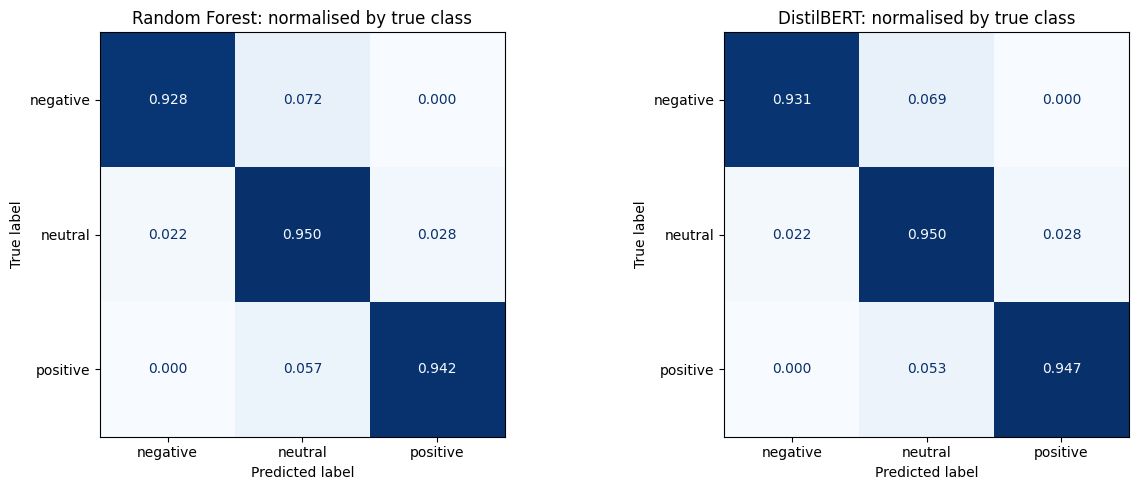

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["negative", "neutral", "positive"]

# Create two side by side panels, one for each model
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# For each model, divide each row of the confusion matrix by its row total so cells show the share of each true class, then draw it as a shaded grid
for ax, (name, preds) in zip(axes, [("Random Forest", y_pred_rf), ("DistilBERT", y_pred_bert)]):
    cm = confusion_matrix(y_true_bert, preds, labels=labels, normalize="true")
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap=plt.cm.Blues, ax=ax, values_format=".3f", colorbar=False)
    ax.set_title(f"{name}: normalised by true class")

plt.tight_layout()

# Save the figure to Drive so it can be logged to MLflow later, then display it
fig.savefig(f"{PROJECT_DIR}/confusion_matrices_normalised.png", dpi=150, bbox_inches="tight")
plt.show()

### Observations

1. DistilBERT got 93.1% of negative, 95.0% of neutral and 94.7% of positive right, against 92.8%, 95.0% and 94.2% for Random Forest.
2. **Errors go almost entirely into neutral.** About 7% of negative and 5% of positive reviews end up as neutral, and negative against positive confusion is effectively zero.
3. DistilBERT's small advantage is in recovering positive and negative reviews that Random Forest called neutral.

### Testing the Trained Sentiment Model

`test_prediction` tokenizes a review, applies softmax to get a probability for each class and returns the top class with its confidence.

I use eight real reviews picked at random from the test set (with a fixed seed) instead of made up sentences, because the reviews use a narrow vocabulary and generic sentences would not be a fair test. Each result shows the true label, prediction, confidence and a tick or cross.

In [ ]:
# Predict the sentiment of a single review and return the predicted label, its confidence and the probabilities for all three classes
def test_prediction(text, model, tokenizer, id2label):
    # Convert the review into token IDs and an attention mask as PyTorch tensors, cut at 128 tokens like the training data
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=128)

    # Move the inputs onto whichever device the model is on (GPU or CPU), dropping token_type_ids which DistilBERT does not accept
    device = next(model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items() if k != "token_type_ids"}

    # Switch the model to evaluation mode and run it without tracking gradients, as no training is happening
    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)

    # Turn the raw output scores into probabilities that sum to 1, and take the class with the highest probability
    probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
    pred = torch.argmax(probs, dim=-1)
    return id2label[pred.item()], probs[0][pred].item(), probs[0].cpu().numpy()

# Pick 8 test reviews at random, using a fixed seed so the same reviews are chosen on every run
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(bert_X_test), 8, replace=False)

# Predict each sampled review and print a tick or cross, the true and predicted labels, the confidence and the first 70 characters of the review
for i in sample_idx:
    text = bert_X_test[i]
    true_label = id2label[bert_y_test[i]]
    pred_label, conf, probs = test_prediction(text, model, tokenizer, id2label)
    match = "✓" if pred_label == true_label else "✗"
    print(f"{match} True: {true_label:8s} | Pred: {pred_label:8s} ({conf:.3f}) | {text[:70]}")

✓ True: positive | Pred: positive (0.984) | The overall price stood out as well worth the cost; we got far more th
✓ True: negative | Pred: negative (0.990) | Our stay in Belfast didn't go as planned. The dining options left a lo
✓ True: neutral  | Pred: neutral  (0.919) | The cost of the stay was in line with similar hotels, nothing more and
✓ True: neutral  | Pred: neutral  (0.922) | Our stay in Southampton was fairly ordinary. In addition, the rate we 
✓ True: positive | Pred: positive (0.985) | Our trip to London got off to a great start here. Meanwhile, the prici
✓ True: positive | Pred: positive (0.984) | Our trip to Southampton got off to a great start here. That said, the 
✓ True: neutral  | Pred: neutral  (0.923) | Our stay in Aberdeen was fairly ordinary. In addition, the surrounding
✓ True: negative | Pred: negative (0.989) | We had high hopes for this hotel in Belfast, but were let down. Plus, 


## MLflow Tracking and Logging

Each model is logged to MLflow with its parameters, test metrics (plus validation scores and training loss for DistilBERT), the confusion matrix and classification report, and the model itself in the Model Registry.

The tracking server is on DagsHub, connected to the project's GitHub repository, so both models sit in the same experiment and can be compared side by side.

`LOG_TO_MLFLOW` controls whether these cells run. I set it to `True` only when recording a new run and back to `False` after, so running the notebook again does not create duplicate runs.

In [ ]:
# Install the DagsHub client, which connects the notebook to the DagsHub repository, and MLflow, which records experiments
!pip install -q dagshub mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.0/274.0 kB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 68.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 67.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.5/228.5 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
import os
import mlflow
import dagshub

# Switch that controls the MLflow cells: True records new runs, False skips logging so Run all does not create duplicates
LOG_TO_MLFLOW = False

# DagsHub account and repository the experiments are logged to
DAGSHUB_USERNAME = "uzoegwuchekwubechris"
DAGSHUB_REPO = "Guest_Experience_Analytics_Topic_Modelling_Sentiment_Analysis_Project"

if LOG_TO_MLFLOW:
    # Connect to the DagsHub repository and point MLflow at its hosted tracking server, signing in through the browser on first use
    dagshub.init(
        repo_owner=DAGSHUB_USERNAME,
        repo_name=DAGSHUB_REPO,
        mlflow=True
    )

    # Group all runs for this project under one named experiment
    mlflow.set_experiment("Montra-Guest-Experience-Analytics")
    print("MLflow tracking URI:", mlflow.get_tracking_uri())

❗❗❗ AUTHORIZATION REQUIRED ❗❗❗

Output()



Open the following link in your browser to authorize the client:
https://dagshub.com/login/oauth/authorize?state=1b3e32f5-06ab-428f-bad6-a9fcf7295a63&client_id=32b60ba385aa7cecf24046d8195a71c07dd345d9657977863b52e7748e0f0f28&middleman_request_id=063fdb6653d38cf81f4af81d5bc300db73bb2e4f9d7bb66fe4cf1cb1f445fb1f




Accessing as uzoegwuchekwubechris

Initialized MLflow to track repo 
"uzoegwuchekwubechris/Guest_Experience_Analytics_Topic_Modelling_Sentiment_Analysis_Project"

Repository uzoegwuchekwubechris/Guest_Experience_Analytics_Topic_Modelling_Sentiment_Analysis_Project initialized!

2026/10/07 23:20:46 INFO mlflow.tracking.fluent: Experiment with name 'Montra-Guest-Experience-Analytics' does not exist. Creating a new experiment.


MLflow tracking URI: https://dagshub.com/uzoegwuchekwubechris/Guest_Experience_Analytics_Topic_Modelling_Sentiment_Analysis_Project.mlflow


In [ ]:
# Log the trained DistilBERT model, its settings, test and validation metrics, and evaluation artifacts to MLflow on DagsHub
from transformers import pipeline
from sklearn.metrics import classification_report

if LOG_TO_MLFLOW:
    labels = ["negative", "neutral", "positive"]

    # Wrap the trained model and tokenizer into a pipeline that takes raw text and returns a score for every class, run on the GPU if available
    sentiment_pipeline = pipeline(
        task="text-classification",
        model=trainer.model,
        tokenizer=tokenizer,
        top_k=None,
        device=0 if torch.cuda.is_available() else -1
    )

    # Evaluate the trained model once on the test set to obtain the final loss and scores
    metrics = trainer.evaluate(eval_dataset=test_dataset)
    print("Evaluation metrics:", metrics)

    # Per class precision and recall on the test set, as a dictionary
    bert_report = classification_report(y_true_bert, y_pred_bert, output_dict=True)

    with mlflow.start_run(run_name="distilbert-sentiment-classification") as run:
        print("Run ID:", run.info.run_id)

        # Record the model and training settings
        mlflow.log_params({
            "model_name": model_name,
            "input_text": "review_text (original)",
            "max_length": 128,
            "num_epochs": training_args.num_train_epochs,
            "batch_size": training_args.per_device_train_batch_size,
            "learning_rate": training_args.learning_rate,
            "best_model_metric": training_args.metric_for_best_model,
            "fp16": training_args.fp16,
            "seed": training_args.seed,
            "train_size": len(train_dataset),
            "validation_size": len(val_dataset),
            "test_size": len(test_dataset),
        })

        # Record the overall test scores
        mlflow.log_metrics({
            "test_accuracy": metrics["eval_accuracy"],
            "test_f1_weighted": metrics["eval_f1_weighted"],
            "test_f1_macro": metrics["eval_f1_macro"],
            "test_loss": metrics["eval_loss"],
        })

        # Record precision and recall for each sentiment class
        for cls in labels:
            mlflow.log_metric(f"test_precision_{cls}", bert_report[cls]["precision"])
            mlflow.log_metric(f"test_recall_{cls}", bert_report[cls]["recall"])

        # Walk through the training history and record validation scores per epoch and training loss per logged step, so MLflow can chart them
        for entry in trainer.state.log_history:
            if "eval_f1_macro" in entry:
                epoch = int(round(entry["epoch"]))
                mlflow.log_metric("val_f1_macro", entry["eval_f1_macro"], step=epoch)
                mlflow.log_metric("val_accuracy", entry["eval_accuracy"], step=epoch)
                mlflow.log_metric("val_loss", entry["eval_loss"], step=epoch)
            elif "loss" in entry:
                mlflow.log_metric("train_loss", entry["loss"], step=entry["step"])

        # Attach the confusion matrix chart and the text classification report
        mlflow.log_artifact(f"{PROJECT_DIR}/confusion_matrices_normalised.png")
        mlflow.log_text(classification_report(y_true_bert, y_pred_bert, digits=4), "classification_report_distilbert.txt")

        # Log the pipeline as an MLflow model and register it in the Model Registry
        mlflow.transformers.log_model(
            transformers_model=sentiment_pipeline,
            name="sentiment_model",
            registered_model_name="montra-sentiment-distilbert"
        )

    print("\nDistilBERT model successfully logged to MLflow!")

Training Loss,Validation Loss,Epoch,Accuracy,F1 Weighted,F1 Macro
0.268353,0.240765,3,0.943558,0.943795,0.944760


Evaluation metrics: {'eval_loss': 0.24076473712921143, 'eval_accuracy': 0.943557748113755, 'eval_f1_weighted': 0.9437946488686622, 'eval_f1_macro': 0.9447600972988351}
Run ID: 21a479739ec04eb2a9200f949f796fe0


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/8.58k [00:00<?, ?B/s]

LICENSE:   0%|          | 0.00/11.4k [00:00<?, ?B/s]

2026/10/07 23:26:08 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/07 23:26:08 WARNING mlflow.utils.requirements_utils: Found torchvision version (0.26.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torchvision==0.26.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/07 23:27:02 WARNING mlflow.utils.requirements_utils: Found torchvision version (0.26.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torchvision==0.26.0' without the loc

🏃 View run distilbert-sentiment-classification at: https://dagshub.com/uzoegwuchekwubechris/Guest_Experience_Analytics_Topic_Modelling_Sentiment_Analysis_Project.mlflow/#/experiments/0/runs/21a479739ec04eb2a9200f949f796fe0
🧪 View experiment at: https://dagshub.com/uzoegwuchekwubechris/Guest_Experience_Analytics_Topic_Modelling_Sentiment_Analysis_Project.mlflow/#/experiments/0

DistilBERT model successfully logged to MLflow!


In [ ]:
# Log the TF-IDF and Random Forest baseline pipeline, its settings, test metrics and classification report to MLflow on DagsHub
from sklearn.pipeline import Pipeline

if LOG_TO_MLFLOW:
    # Join the fitted TF-IDF vectoriser and Random Forest into one pipeline, so the logged model accepts processed text directly
    rf_pipeline = Pipeline([("tfidf", tfidf), ("model", rf_model)])

    # Retrieve the Random Forest scores from the comparison table, and its per class precision and recall
    rf_scores = next(r for r in model_results if r["model"] == "Random Forest")
    rf_report = classification_report(y_test, y_pred_rf, output_dict=True)

    with mlflow.start_run(run_name="random-forest-tfidf-baseline") as run:
        print("Run ID:", run.info.run_id)

        # Record the feature extraction and model settings
        mlflow.log_params({
            "model_name": "RandomForestClassifier",
            "input_text": "processed_text",
            "tfidf_ngram_range": "(1, 2)",
            "tfidf_min_df": 2,
            "tfidf_max_df": 0.95,
            "tfidf_max_features": 10000,
            "tfidf_vocabulary_size": len(tfidf.vocabulary_),
            "n_estimators": rf_model.n_estimators,
            "class_weight": "balanced",
            "random_state": 42,
            "train_size": X_train_tfidf.shape[0],
            "test_size": X_test_tfidf.shape[0],
        })

        # Record the overall test scores
        mlflow.log_metrics({
            "test_accuracy": rf_scores["accuracy"],
            "test_f1_weighted": rf_scores["f1_weighted"],
            "test_f1_macro": rf_scores["f1_macro"],
        })

        # Record precision and recall for each sentiment class
        for cls in ["negative", "neutral", "positive"]:
            mlflow.log_metric(f"test_precision_{cls}", rf_report[cls]["precision"])
            mlflow.log_metric(f"test_recall_{cls}", rf_report[cls]["recall"])

        # Attach the text classification report
        mlflow.log_text(classification_report(y_test, y_pred_rf, digits=4), "classification_report_random_forest.txt")

        # Log the TF-IDF and Random Forest pipeline as an MLflow model and register it, marking the decision tree type as trusted because the model was built in this session rather than loaded from an outside file
        mlflow.sklearn.log_model(
            sk_model=rf_pipeline,
            name="sentiment_model",
            registered_model_name="montra-sentiment-random-forest",
            skops_trusted_types=["sklearn.tree._tree.Tree"]
        )

    print("\nRandom Forest model successfully logged to MLflow!")

Run ID: 3bdf5e1a87474cdab0abe06a45438701


Successfully registered model 'montra-sentiment-random-forest'.
2026/10/07 23:36:29 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: montra-sentiment-random-forest, version 1
Created version '1' of model 'montra-sentiment-random-forest'.


🏃 View run random-forest-tfidf-baseline at: https://dagshub.com/uzoegwuchekwubechris/Guest_Experience_Analytics_Topic_Modelling_Sentiment_Analysis_Project.mlflow/#/experiments/0/runs/3bdf5e1a87474cdab0abe06a45438701
🧪 View experiment at: https://dagshub.com/uzoegwuchekwubechris/Guest_Experience_Analytics_Topic_Modelling_Sentiment_Analysis_Project.mlflow/#/experiments/0

Random Forest model successfully logged to MLflow!
